In [1]:

import torch
import torchvision
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("Random Seed:", SEED)


PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU Available: True
GPU Name: Tesla T4
Random Seed: 42


In [2]:

from torchvision import datasets

# Download original CIFAR-10 datasets
train_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True
)

test_full = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

print("Full training images:", len(train_full))
print("Original test images:", len(test_full))
print("Classes:", train_full.classes)


100%|██████████| 170M/170M [40:24<00:00, 70.3kB/s]


Full training images: 50000
Original test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:

import numpy as np
from collections import Counter

# Fixed seed for reproducible dataset selection
SPLIT_SEED = 42
rng = np.random.default_rng(SPLIT_SEED)

labels = np.array(train_full.targets)

train_indices = []
val_indices = []

for class_id in range(10):
    class_indices = np.where(labels == class_id)[0]

    selected = rng.choice(
        class_indices,
        size=50,
        replace=False
    )

    # 40 training and 10 validation per class
    train_indices.extend(selected[:40])
    val_indices.extend(selected[40:])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

train_small_indices = np.concatenate(
    [train_indices, val_indices]
)

print("Selected images:", len(train_small_indices))
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))

print("Training class distribution:")
print(Counter(labels[train_indices]))

print("Validation class distribution:")
print(Counter(labels[val_indices]))

print("Overlap:", len(set(train_indices) & set(val_indices)))
print("Split seed:", SPLIT_SEED)


Selected images: 500
Training images: 400
Validation images: 100
Training class distribution:
Counter({np.int64(0): 40, np.int64(1): 40, np.int64(2): 40, np.int64(3): 40, np.int64(4): 40, np.int64(5): 40, np.int64(6): 40, np.int64(7): 40, np.int64(8): 40, np.int64(9): 40})
Validation class distribution:
Counter({np.int64(0): 10, np.int64(1): 10, np.int64(2): 10, np.int64(3): 10, np.int64(4): 10, np.int64(5): 10, np.int64(6): 10, np.int64(7): 10, np.int64(8): 10, np.int64(9): 10})
Overlap: 0
Split seed: 42


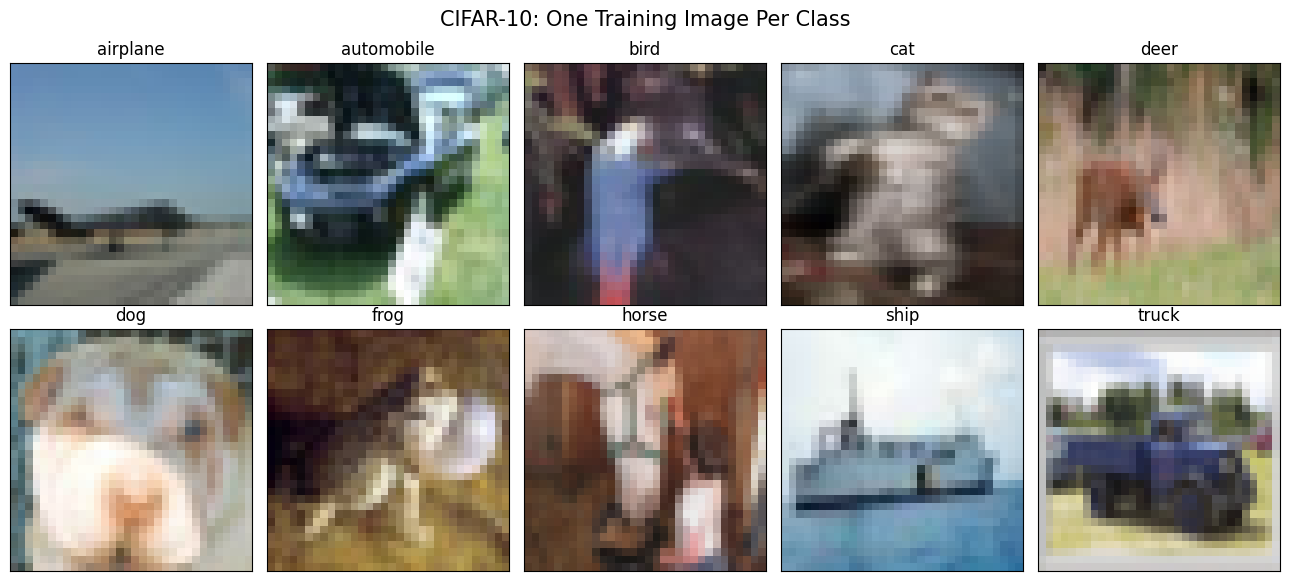

In [4]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for class_id, ax in enumerate(axes.flat):
    # Find a selected training image for this class
    matching_indices = [
        idx for idx in train_indices
        if labels[idx] == class_id
    ]

    image, label = train_full[matching_indices[0]]

    ax.imshow(image)
    ax.set_title(train_full.classes[label])
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("CIFAR-10: One Training Image Per Class",
             fontsize=15)
plt.tight_layout()
plt.show()


In [5]:

from torch.utils.data import DataLoader, Subset
from torchvision import transforms

# Basic preprocessing (no augmentation)
basic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Use original CIFAR-10 training images
prepared_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=basic_transform
)

# Apply our previously created indices
train_dataset = Subset(
    prepared_dataset,
    train_indices.tolist()
)

val_dataset = Subset(
    prepared_dataset,
    val_indices.tolist()
)

# Create reproducible training loader
loader_generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=loader_generator,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Verify a training batch
images, targets = next(iter(train_loader))

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", targets.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))


Training dataset: 400
Validation dataset: 100
Image batch shape: torch.Size([32, 3, 32, 32])
Label batch shape: torch.Size([32])
Number of training batches: 13
Number of validation batches: 4


In [6]:

import torch
import torch.nn as nn

class InceptionModule(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        # Branch 1: 1x1 convolution
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU()
        )

        # Branch 2: 1x1 reduction + 3x3 convolution
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU()
        )

        # Branch 3: 1x1 reduction + 5x5 convolution
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, 8, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=5, padding=2),
            nn.ReLU()
        )

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)

        return torch.cat([b1, b2, b3], dim=1)

# Test the module using artificial input
module = InceptionModule(in_channels=32)

dummy_input = torch.randn(1, 32, 16, 16)
dummy_output = module(dummy_input)

parameters = sum(
    p.numel() for p in module.parameters()
    if p.requires_grad
)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)
print("Module parameters:", parameters)


Input shape: torch.Size([1, 32, 16, 16])
Output shape: torch.Size([1, 64, 16, 16])
Module parameters: 9176


In [7]:

import torch
import torch.nn as nn

class SmallInceptionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # First convolution block
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Inception module defined in Step 5.2
        self.inception = InceptionModule(32)

        # Second convolution block
        self.conv2 = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        # Global Average Pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # Final classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.inception(x)
        x = self.conv2(x)
        x = self.gap(x)
        x = self.classifier(x)
        return x


# Initialize model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SmallInceptionCNN().to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Test with dummy CIFAR-10 images
dummy = torch.randn(4, 3, 32, 32).to(device)

with torch.no_grad():
    output = model(dummy)

print("Device:", device)
print("Total trainable parameters:", total_params)
print("Input shape:", dummy.shape)
print("Output shape:", output.shape)
print("Under 1M parameter limit:", total_params <= 1_000_000)


Device: cuda
Total trainable parameters: 85538
Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])
Under 1M parameter limit: True


In [8]:

import torch.optim as optim

# Loss function for 10-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Loss Function:", criterion)
print("Optimizer:", type(optimizer).__name__)
print("Learning Rate:", optimizer.param_groups[0]["lr"])
print("Weight Decay:", optimizer.param_groups[0]["weight_decay"])
print("Number of Classes:", 10)


Loss Function: CrossEntropyLoss()
Optimizer: AdamW
Learning Rate: 0.001
Weight Decay: 0.0001
Number of Classes: 10


In [9]:

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / total
    val_accuracy = 100 * correct / total

    return val_loss, val_accuracy


print("Training and validation functions created successfully!")


Training and validation functions created successfully!


In [10]:

# Fresh initialization for baseline trial
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Fresh model and optimizer
baseline_model = SmallInceptionCNN().to(device)

baseline_optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

baseline_criterion = nn.CrossEntropyLoss()

print("Baseline model initialized!")
print("Seed:", SEED)
print("Device:", device)
print("Parameters:", sum(
    p.numel() for p in baseline_model.parameters()
    if p.requires_grad
))


Baseline model initialized!
Seed: 42
Device: cuda
Parameters: 85538


In [11]:

trial_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(5):

    train_loss, train_acc = train_one_epoch(
        baseline_model,
        train_loader,
        baseline_optimizer,
        baseline_criterion,
        device
    )

    val_loss, val_acc = validate(
        baseline_model,
        val_loader,
        baseline_criterion,
        device
    )

    trial_history["train_loss"].append(train_loss)
    trial_history["train_acc"].append(train_acc)
    trial_history["val_loss"].append(val_loss)
    trial_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )


Epoch 1/5 | Train Loss: 2.2472 | Train Acc: 16.00% | Val Loss: 2.2396 | Val Acc: 19.00%
Epoch 2/5 | Train Loss: 1.9772 | Train Acc: 25.75% | Val Loss: 2.0719 | Val Acc: 26.00%
Epoch 3/5 | Train Loss: 1.8687 | Train Acc: 33.50% | Val Loss: 1.9185 | Val Acc: 24.00%
Epoch 4/5 | Train Loss: 1.7953 | Train Acc: 39.75% | Val Loss: 1.8359 | Val Acc: 27.00%
Epoch 5/5 | Train Loss: 1.7161 | Train Acc: 40.25% | Val Loss: 1.8104 | Val Acc: 28.00%


In [12]:

import copy

MAX_EPOCHS = 60
EXPERIMENT_SEEDS = [42, 123, 2026]

def make_fresh_model(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    fresh_model = SmallInceptionCNN().to(device)

    fresh_optimizer = torch.optim.AdamW(
        fresh_model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    return fresh_model, fresh_optimizer


def initialize_history():
    return {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }


print("Maximum epochs:", MAX_EPOCHS)
print("Experiment seeds:", EXPERIMENT_SEEDS)
print("Fresh model function ready!")
print("Training history function ready!")


Maximum epochs: 60
Experiment seeds: [42, 123, 2026]
Fresh model function ready!
Training history function ready!


In [13]:

# Reproducible baseline experiment — Seed 42

RUN_SEED = 42

# Initialize a fresh model and optimizer
baseline_model, baseline_optimizer = make_fresh_model(
    RUN_SEED
)

baseline_criterion = nn.CrossEntropyLoss()

# Fresh, reproducibly shuffled training DataLoader
baseline_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(RUN_SEED),
    num_workers=2
)

# Validation DataLoader (no shuffle)
baseline_val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Store learning curves
baseline_history = initialize_history()

# Best-checkpoint tracking
best_val_accuracy = -1.0
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

print("Experiment: Baseline (No Augmentation)")
print("Seed:", RUN_SEED)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Maximum epochs:", MAX_EPOCHS)
print("Train batches:", len(baseline_train_loader))
print("Validation batches:", len(baseline_val_loader))
print("Model initialized successfully!")


Experiment: Baseline (No Augmentation)
Seed: 42
Training images: 400
Validation images: 100
Maximum epochs: 60
Train batches: 13
Validation batches: 4
Model initialized successfully!


In [14]:

import copy
import time

start_time = time.time()

for epoch in range(MAX_EPOCHS):

    # Train for one epoch
    train_loss, train_acc = train_one_epoch(
        baseline_model,
        baseline_train_loader,
        baseline_optimizer,
        baseline_criterion,
        device
    )

    # Evaluate on validation set only
    val_loss, val_acc = validate(
        baseline_model,
        baseline_val_loader,
        baseline_criterion,
        device
    )

    # Record learning curves
    baseline_history["train_loss"].append(train_loss)
    baseline_history["train_acc"].append(train_acc)
    baseline_history["val_loss"].append(val_loss)
    baseline_history["val_acc"].append(val_acc)

    # Select the best checkpoint using validation only
    if (
        val_acc > best_val_accuracy
        or (
            val_acc == best_val_accuracy
            and val_loss < best_val_loss
        )
    ):
        best_val_accuracy = val_acc
        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            baseline_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

elapsed = time.time() - start_time

# Save best model and training history
torch.save({
    "model_state_dict": best_model_state,
    "seed": RUN_SEED,
    "best_epoch": best_epoch,
    "best_val_accuracy": best_val_accuracy,
    "best_val_loss": best_val_loss,
    "history": baseline_history,
    "train_indices": train_indices.tolist(),
    "val_indices": val_indices.tolist(),
    "split_seed": SPLIT_SEED
}, "baseline_seed42_best.pth")

print("\n========== BASELINE SUMMARY ==========")
print("Seed:", RUN_SEED)
print("Epochs completed:", MAX_EPOCHS)
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training duration: {elapsed / 60:.2f} minutes")
print("Checkpoint saved: baseline_seed42_best.pth")


Epoch 01/60 | Train Loss: 2.1877 | Train Acc: 16.00% | Val Loss: 2.2229 | Val Acc: 22.00%
Epoch 02/60 | Train Loss: 1.9620 | Train Acc: 29.25% | Val Loss: 2.0560 | Val Acc: 27.00%
Epoch 03/60 | Train Loss: 1.8545 | Train Acc: 33.00% | Val Loss: 1.8864 | Val Acc: 26.00%
Epoch 04/60 | Train Loss: 1.7782 | Train Acc: 35.75% | Val Loss: 1.8523 | Val Acc: 29.00%
Epoch 05/60 | Train Loss: 1.7218 | Train Acc: 39.00% | Val Loss: 1.7615 | Val Acc: 31.00%
Epoch 06/60 | Train Loss: 1.6942 | Train Acc: 37.50% | Val Loss: 1.7432 | Val Acc: 27.00%
Epoch 07/60 | Train Loss: 1.6004 | Train Acc: 43.25% | Val Loss: 1.7449 | Val Acc: 33.00%
Epoch 08/60 | Train Loss: 1.5811 | Train Acc: 47.50% | Val Loss: 1.7001 | Val Acc: 34.00%
Epoch 09/60 | Train Loss: 1.5225 | Train Acc: 51.25% | Val Loss: 1.7352 | Val Acc: 34.00%
Epoch 10/60 | Train Loss: 1.4699 | Train Acc: 50.25% | Val Loss: 1.6448 | Val Acc: 32.00%
Epoch 11/60 | Train Loss: 1.4028 | Train Acc: 53.75% | Val Loss: 1.6217 | Val Acc: 40.00%
Epoch 12/6

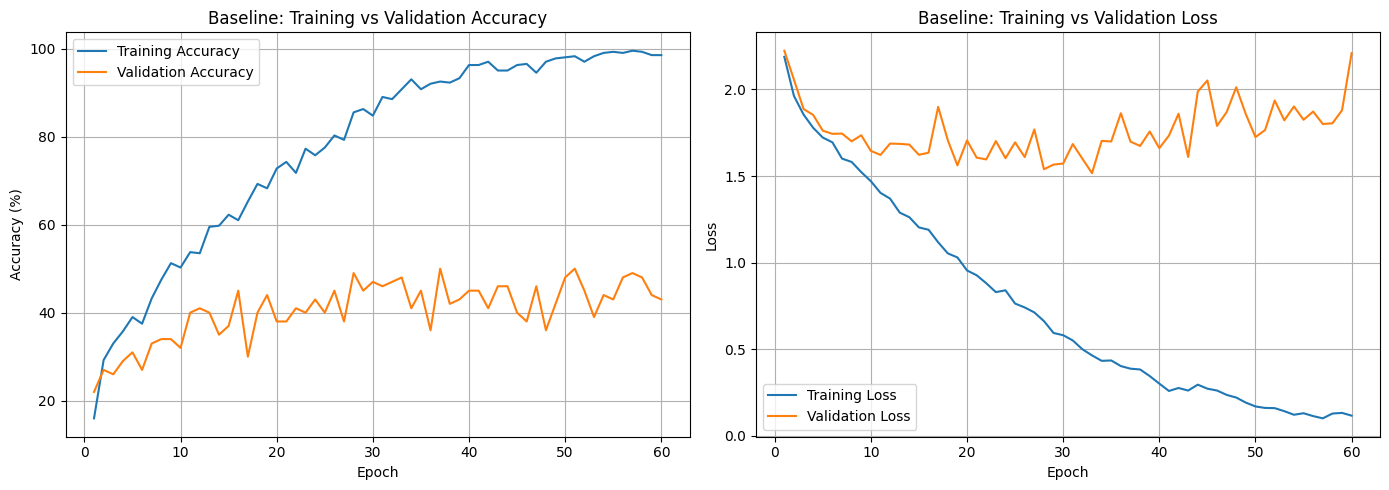

========== BASELINE RESULTS ==========
Epochs completed: 60
Best epoch: 37
Best validation accuracy: 50.00%
Best validation loss: 1.6984
Final training accuracy: 98.50%
Final validation accuracy: 43.00%
Graph saved successfully!


In [15]:

import matplotlib.pyplot as plt

epochs = range(
    1,
    len(baseline_history["train_acc"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curve
axes[0].plot(
    epochs,
    baseline_history["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    baseline_history["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Baseline: Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

# Loss curve
axes[1].plot(
    epochs,
    baseline_history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    baseline_history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Baseline: Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(
    "baseline_seed42_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("========== BASELINE RESULTS ==========")
print("Epochs completed:", len(baseline_history["train_acc"]))
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Final training accuracy: {baseline_history['train_acc'][-1]:.2f}%")
print(f"Final validation accuracy: {baseline_history['val_acc'][-1]:.2f}%")
print("Graph saved successfully!")


In [16]:

import os

checkpoint_path = "baseline_seed42_best.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    print("Saved seed:", checkpoint["seed"])
    print("Saved best epoch:", checkpoint["best_epoch"])
    print(
        "Saved validation accuracy:",
        f"{checkpoint['best_val_accuracy']:.2f}%"
    )

    # Recreate the best model
    best_baseline_model = SmallInceptionCNN().to(device)

    best_baseline_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_baseline_model.eval()

    # Re-evaluate on validation set
    loss, accuracy = validate(
        best_baseline_model,
        val_loader,
        nn.CrossEntropyLoss(),
        device
    )

    print(f"Reloaded validation accuracy: {accuracy:.2f}%")
    print("Checkpoint verification complete!")


Checkpoint exists: True
Saved seed: 42
Saved best epoch: 37
Saved validation accuracy: 50.00%
Reloaded validation accuracy: 50.00%
Checkpoint verification complete!


In [17]:

from torchvision import transforms

# Geometric augmentation for training images only
geometric_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Training dataset with geometric augmentation
geometric_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=geometric_transform
)

geometric_train_dataset = Subset(
    geometric_full_dataset,
    train_indices.tolist()
)

# Validation remains unchanged
geometric_val_dataset = val_dataset

print("Geometric training images:",
      len(geometric_train_dataset))

print("Validation images:",
      len(geometric_val_dataset))

print("Training augmentation:")
print(geometric_transform)

print("Geometric augmentation ready!")


Geometric training images: 400
Validation images: 100
Training augmentation:
Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-25.0, 25.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)
Geometric augmentation ready!


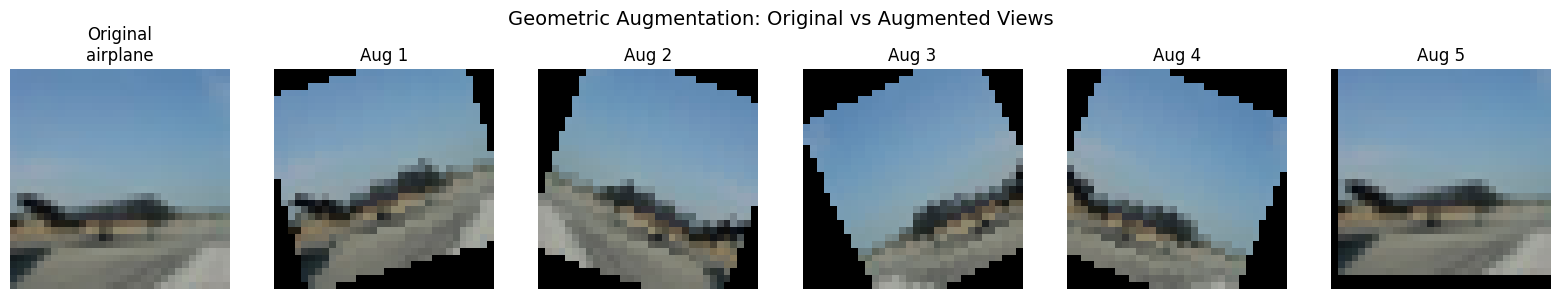

In [18]:
import matplotlib.pyplot as plt
from torchvision import transforms

# Original image without transform
sample_index = train_indices[0]
original_image, original_label = train_full[sample_index]

# Separate transform for display only (without normalization)
display_geometric_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=25)
])

# Create multiple augmented versions
augmented_images = [display_geometric_transform(original_image) for _ in range(5)]

# Plot original + augmentations
fig, axes = plt.subplots(1, 6, figsize=(16, 3))

axes[0].imshow(original_image)
axes[0].set_title(f"Original\n{train_full.classes[original_label]}")
axes[0].axis("off")

for i in range(5):
    axes[i+1].imshow(augmented_images[i])
    axes[i+1].set_title(f"Aug {i+1}")
    axes[i+1].axis("off")

plt.suptitle("Geometric Augmentation: Original vs Augmented Views", fontsize=14)
plt.tight_layout()
plt.show()

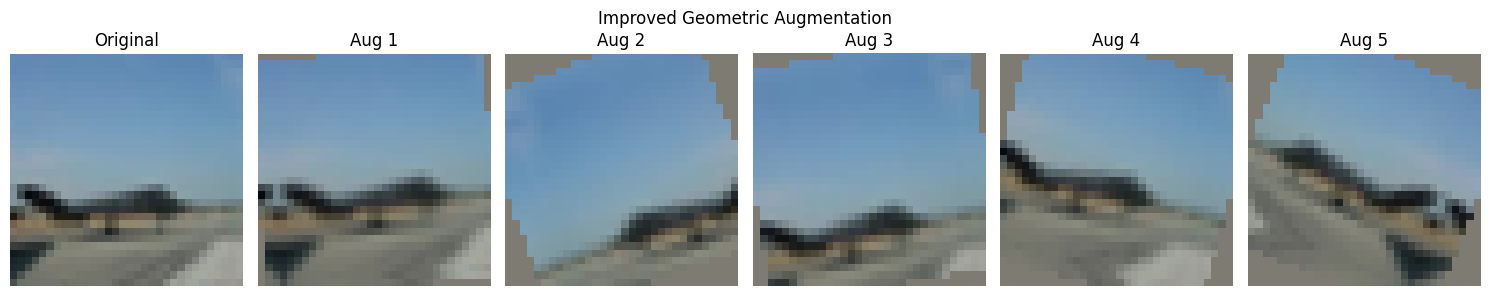

Training images: 400
Validation images: 100
Improved geometric augmentation ready!


In [19]:

from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Improved geometric augmentation
geometric_transform = transforms.Compose([
    transforms.RandomCrop(
        32,
        padding=4,
        padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Display transform (same geometry, no normalization)
display_transform = transforms.Compose([
    transforms.RandomCrop(
        32,
        padding=4,
        padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    )
])

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(5):
    augmented = display_transform(original_image)
    axes[i + 1].imshow(augmented)
    axes[i + 1].set_title(f"Aug {i+1}")
    axes[i + 1].axis("off")

plt.suptitle("Improved Geometric Augmentation")
plt.tight_layout()
plt.show()

# Recreate training dataset using improved transform
geometric_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=geometric_transform
)

geometric_train_dataset = Subset(
    geometric_full_dataset,
    train_indices.tolist()
)

print("Training images:", len(geometric_train_dataset))
print("Validation images:", len(val_dataset))
print("Improved geometric augmentation ready!")


In [20]:

# Geometric-only experiment, seed 42
GEO_SEED = 42

# Initialize a fresh model
geo_model, geo_optimizer = make_fresh_model(
    GEO_SEED
)

geo_criterion = nn.CrossEntropyLoss()

# Reproducible training DataLoader
geo_train_loader = DataLoader(
    geometric_train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(GEO_SEED),
    num_workers=2
)

# Validation without augmentation
geo_val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

geo_history = initialize_history()

geo_best_val_acc = -1.0
geo_best_val_loss = float("inf")
geo_best_epoch = 0
geo_best_state = None

print("Experiment: Geometric Only")
print("Seed:", GEO_SEED)
print("Training images:", len(geo_train_loader.dataset))
print("Validation images:", len(geo_val_loader.dataset))
print("Training batches:", len(geo_train_loader))
print("Validation batches:", len(geo_val_loader))
print("Model parameters:", sum(
    p.numel() for p in geo_model.parameters()
    if p.requires_grad
))
print("Ready for geometric-only training!")


Experiment: Geometric Only
Seed: 42
Training images: 400
Validation images: 100
Training batches: 13
Validation batches: 4
Model parameters: 85538
Ready for geometric-only training!


In [21]:

import copy
import time

geo_start_time = time.time()

for epoch in range(MAX_EPOCHS):

    # Train using geometrically augmented images
    train_loss, train_acc = train_one_epoch(
        geo_model,
        geo_train_loader,
        geo_optimizer,
        geo_criterion,
        device
    )

    # Validation on original, unaugmented images
    val_loss, val_acc = validate(
        geo_model,
        geo_val_loader,
        geo_criterion,
        device
    )

    # Record results
    geo_history["train_loss"].append(train_loss)
    geo_history["train_acc"].append(train_acc)
    geo_history["val_loss"].append(val_loss)
    geo_history["val_acc"].append(val_acc)

    # Save best model based on validation performance
    if (
        val_acc > geo_best_val_acc
        or (
            val_acc == geo_best_val_acc
            and val_loss < geo_best_val_loss
        )
    ):
        geo_best_val_acc = val_acc
        geo_best_val_loss = val_loss
        geo_best_epoch = epoch + 1

        geo_best_state = copy.deepcopy(
            geo_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

geo_elapsed = time.time() - geo_start_time

# Save checkpoint and history
torch.save({
    "model_state_dict": geo_best_state,
    "seed": GEO_SEED,
    "best_epoch": geo_best_epoch,
    "best_val_accuracy": geo_best_val_acc,
    "best_val_loss": geo_best_val_loss,
    "history": geo_history,
    "train_indices": train_indices.tolist(),
    "val_indices": val_indices.tolist(),
    "split_seed": SPLIT_SEED,
    "augmentation": "Geometric"
}, "geometric_seed42_best.pth")

print("\n========== GEOMETRIC-ONLY SUMMARY ==========")
print("Seed:", GEO_SEED)
print("Epochs completed:", len(geo_history["train_acc"]))
print("Best epoch:", geo_best_epoch)
print(f"Best validation accuracy: {geo_best_val_acc:.2f}%")
print(f"Best validation loss: {geo_best_val_loss:.4f}")
print(f"Final training accuracy: {geo_history['train_acc'][-1]:.2f}%")
print(f"Final validation accuracy: {geo_history['val_acc'][-1]:.2f}%")
print(f"Training duration: {geo_elapsed/60:.2f} minutes")
print("Checkpoint saved: geometric_seed42_best.pth")


Epoch 01/60 | Train Loss: 2.2028 | Train Acc: 15.50% | Val Loss: 2.2229 | Val Acc: 22.00%
Epoch 02/60 | Train Loss: 2.0069 | Train Acc: 25.75% | Val Loss: 2.0507 | Val Acc: 25.00%
Epoch 03/60 | Train Loss: 1.9194 | Train Acc: 28.25% | Val Loss: 1.8869 | Val Acc: 29.00%
Epoch 04/60 | Train Loss: 1.8517 | Train Acc: 29.50% | Val Loss: 1.8718 | Val Acc: 29.00%
Epoch 05/60 | Train Loss: 1.8134 | Train Acc: 36.25% | Val Loss: 1.7928 | Val Acc: 36.00%
Epoch 06/60 | Train Loss: 1.7985 | Train Acc: 31.75% | Val Loss: 1.7698 | Val Acc: 32.00%
Epoch 07/60 | Train Loss: 1.7387 | Train Acc: 35.75% | Val Loss: 1.7578 | Val Acc: 33.00%
Epoch 08/60 | Train Loss: 1.7383 | Train Acc: 37.50% | Val Loss: 1.7541 | Val Acc: 33.00%
Epoch 09/60 | Train Loss: 1.7000 | Train Acc: 36.25% | Val Loss: 1.7674 | Val Acc: 35.00%
Epoch 10/60 | Train Loss: 1.6508 | Train Acc: 39.25% | Val Loss: 1.7212 | Val Acc: 32.00%
Epoch 11/60 | Train Loss: 1.6332 | Train Acc: 41.50% | Val Loss: 1.6922 | Val Acc: 40.00%
Epoch 12/6

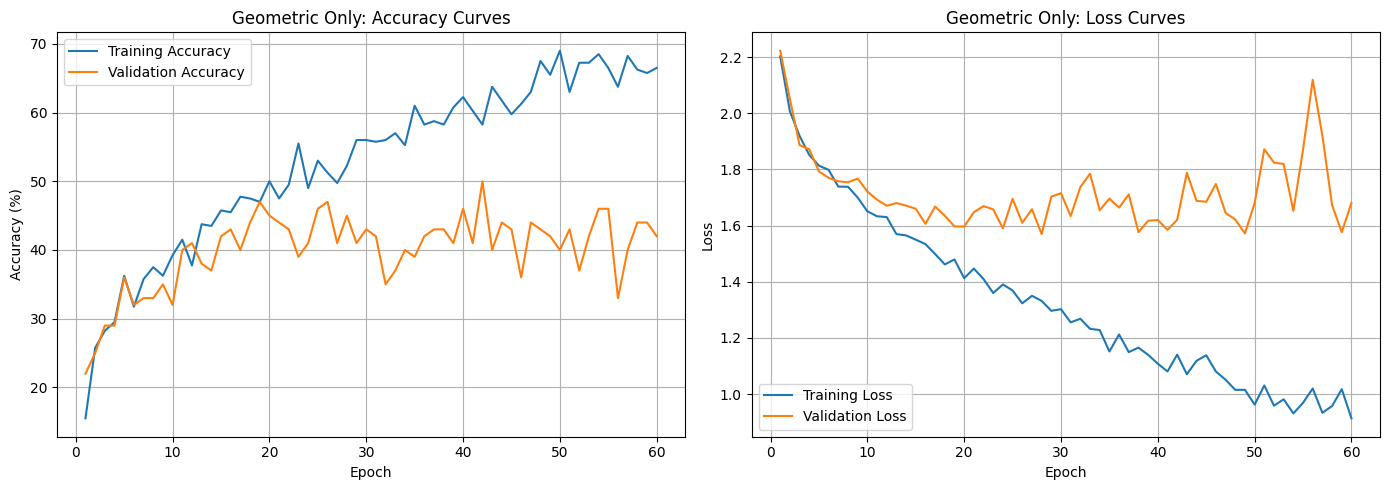

========== COMPARISON ==========
Baseline best val: 50.00%
Geometric best val: 50.00%
Difference: +0.00 percentage points
Geometric learning curves saved!


In [22]:

import matplotlib.pyplot as plt

geo_epochs = range(
    1,
    len(geo_history["train_acc"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    geo_epochs,
    geo_history["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    geo_epochs,
    geo_history["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Geometric Only: Accuracy Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    geo_epochs,
    geo_history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    geo_epochs,
    geo_history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Geometric Only: Loss Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    "geometric_seed42_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== COMPARISON ==========")
print(f"Baseline best val: {best_val_accuracy:.2f}%")
print(f"Geometric best val: {geo_best_val_acc:.2f}%")
print(
    f"Difference: {geo_best_val_acc - best_val_accuracy:+.2f} percentage points"
)
print("Geometric learning curves saved!")


In [23]:

from torchvision import transforms
import torch

# Custom Gaussian noise augmentation
class AddGaussianNoise:
    def __init__(self, std=0.05, p=0.5):
        self.std = std
        self.p = p

    def __call__(self, tensor):
        if torch.rand(1).item() < self.p:
            noise = torch.randn_like(tensor) * self.std
            tensor = torch.clamp(tensor + noise, 0.0, 1.0)
        return tensor


# Photometric augmentation
photometric_transform = transforms.Compose([
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.4),

    transforms.ToTensor(),

    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Training data with photometric augmentation
photometric_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=photometric_transform
)

photo_train_dataset = Subset(
    photometric_full_dataset,
    train_indices.tolist()
)

# Validation stays clean
photo_val_dataset = val_dataset

print("Photometric training images:", len(photo_train_dataset))
print("Validation images:", len(photo_val_dataset))
print("Photometric augmentation ready!")


Photometric training images: 400
Validation images: 100
Photometric augmentation ready!


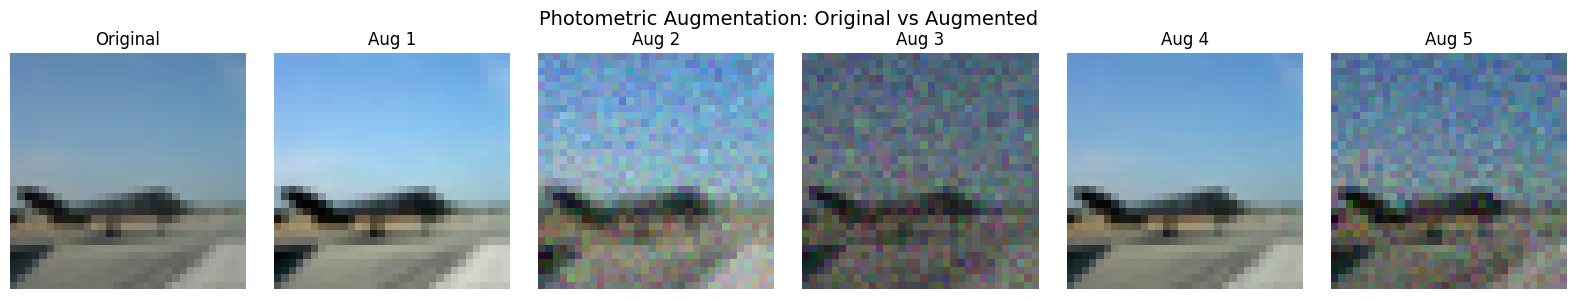

Photometric visualization complete!


In [24]:

import matplotlib.pyplot as plt
from torchvision import transforms

# Display transform without normalization
# Same augmentations as training
display_photo_transform = transforms.Compose([
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.4),

    transforms.ToTensor(),

    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.ToPILImage()
])

# Use same original airplane image
sample_index = train_indices[0]
original_image, original_label = train_full[sample_index]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))

axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(5):
    augmented = display_photo_transform(original_image)
    axes[i+1].imshow(augmented)
    axes[i+1].set_title(f"Aug {i+1}")
    axes[i+1].axis("off")

plt.suptitle(
    "Photometric Augmentation: Original vs Augmented",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Photometric visualization complete!")


In [25]:

# Photometric-only experiment
PHOTO_SEED = 42

# Fresh model and optimizer
photo_model, photo_optimizer = make_fresh_model(
    PHOTO_SEED
)

photo_criterion = nn.CrossEntropyLoss()

# Training with photometric augmentation
photo_train_loader = DataLoader(
    photo_train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(PHOTO_SEED),
    num_workers=2
)

# Clean validation, no augmentation
photo_val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Training history
photo_history = initialize_history()

# Best checkpoint variables
photo_best_val_acc = -1.0
photo_best_val_loss = float("inf")
photo_best_epoch = 0
photo_best_state = None

print("Experiment: Photometric Only")
print("Seed:", PHOTO_SEED)
print("Training images:", len(photo_train_loader.dataset))
print("Validation images:", len(photo_val_loader.dataset))
print("Training batches:", len(photo_train_loader))
print("Validation batches:", len(photo_val_loader))
print("Model parameters:", sum(
    p.numel() for p in photo_model.parameters()
    if p.requires_grad
))
print("Photometric-only model ready!")


Experiment: Photometric Only
Seed: 42
Training images: 400
Validation images: 100
Training batches: 13
Validation batches: 4
Model parameters: 85538
Photometric-only model ready!


In [26]:

import copy
import time

photo_start_time = time.time()

# Train for 60 epochs
for epoch in range(MAX_EPOCHS):

    # Training with photometric augmentation
    train_loss, train_acc = train_one_epoch(
        photo_model,
        photo_train_loader,
        photo_optimizer,
        photo_criterion,
        device
    )

    # Validation without augmentation
    val_loss, val_acc = validate(
        photo_model,
        photo_val_loader,
        photo_criterion,
        device
    )

    # Store learning curves
    photo_history["train_loss"].append(train_loss)
    photo_history["train_acc"].append(train_acc)
    photo_history["val_loss"].append(val_loss)
    photo_history["val_acc"].append(val_acc)

    # Select best checkpoint using validation only
    if (
        val_acc > photo_best_val_acc
        or (
            val_acc == photo_best_val_acc
            and val_loss < photo_best_val_loss
        )
    ):
        photo_best_val_acc = val_acc
        photo_best_val_loss = val_loss
        photo_best_epoch = epoch + 1

        photo_best_state = copy.deepcopy(
            photo_model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

photo_elapsed = time.time() - photo_start_time

# Save the best checkpoint and experiment details
torch.save({
    "model_state_dict": photo_best_state,
    "seed": PHOTO_SEED,
    "best_epoch": photo_best_epoch,
    "best_val_accuracy": photo_best_val_acc,
    "best_val_loss": photo_best_val_loss,
    "history": photo_history,
    "train_indices": train_indices.tolist(),
    "val_indices": val_indices.tolist(),
    "split_seed": SPLIT_SEED,
    "augmentation": "Photometric"
}, "photometric_seed42_best.pth")

print("\n========== PHOTOMETRIC-ONLY SUMMARY ==========")
print("Seed:", PHOTO_SEED)
print("Epochs completed:", len(photo_history["train_acc"]))
print("Best epoch:", photo_best_epoch)
print(f"Best validation accuracy: {photo_best_val_acc:.2f}%")
print(f"Best validation loss: {photo_best_val_loss:.4f}")
print(f"Final training accuracy: {photo_history['train_acc'][-1]:.2f}%")
print(f"Final validation accuracy: {photo_history['val_acc'][-1]:.2f}%")
print(f"Training duration: {photo_elapsed/60:.2f} minutes")
print("Checkpoint saved: photometric_seed42_best.pth")


Epoch 01/60 | Train Loss: 2.2400 | Train Acc: 15.50% | Val Loss: 2.2393 | Val Acc: 24.00%
Epoch 02/60 | Train Loss: 2.0541 | Train Acc: 22.00% | Val Loss: 2.1038 | Val Acc: 21.00%
Epoch 03/60 | Train Loss: 1.9666 | Train Acc: 25.25% | Val Loss: 1.9316 | Val Acc: 19.00%
Epoch 04/60 | Train Loss: 1.9048 | Train Acc: 31.75% | Val Loss: 1.9004 | Val Acc: 26.00%
Epoch 05/60 | Train Loss: 1.8600 | Train Acc: 33.25% | Val Loss: 1.8199 | Val Acc: 30.00%
Epoch 06/60 | Train Loss: 1.8453 | Train Acc: 31.50% | Val Loss: 1.7544 | Val Acc: 33.00%
Epoch 07/60 | Train Loss: 1.7673 | Train Acc: 37.00% | Val Loss: 1.7759 | Val Acc: 27.00%
Epoch 08/60 | Train Loss: 1.7520 | Train Acc: 38.25% | Val Loss: 1.7635 | Val Acc: 33.00%
Epoch 09/60 | Train Loss: 1.7012 | Train Acc: 39.50% | Val Loss: 1.7164 | Val Acc: 39.00%
Epoch 10/60 | Train Loss: 1.6951 | Train Acc: 38.50% | Val Loss: 1.6792 | Val Acc: 36.00%
Epoch 11/60 | Train Loss: 1.6134 | Train Acc: 43.00% | Val Loss: 1.6792 | Val Acc: 34.00%
Epoch 12/6

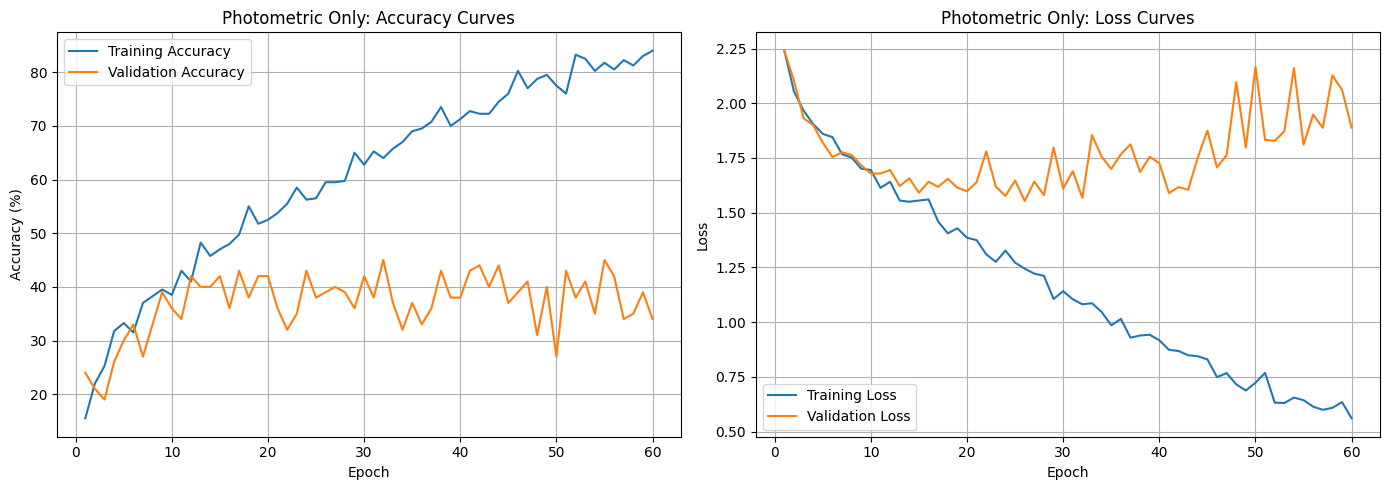

Photometric learning curves saved!
Best epoch: 32
Best validation accuracy: 45.00%


In [27]:

import matplotlib.pyplot as plt

photo_epochs = range(
    1,
    len(photo_history["train_acc"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
axes[0].plot(
    photo_epochs,
    photo_history["train_acc"],
    label="Training Accuracy"
)

axes[0].plot(
    photo_epochs,
    photo_history["val_acc"],
    label="Validation Accuracy"
)

axes[0].set_title("Photometric Only: Accuracy Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True)

# Loss curves
axes[1].plot(
    photo_epochs,
    photo_history["train_loss"],
    label="Training Loss"
)

axes[1].plot(
    photo_epochs,
    photo_history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Photometric Only: Loss Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    "photometric_seed42_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Photometric learning curves saved!")
print("Best epoch:", photo_best_epoch)
print(f"Best validation accuracy: {photo_best_val_acc:.2f}%")


In [28]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import torch

# Combined geometric + photometric augmentation
combined_transform = transforms.Compose([
    # Geometric
    transforms.RandomCrop(
        32,
        padding=4,
        padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    ),

    # Photometric
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),

    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.4),

    transforms.ToTensor(),

    AddGaussianNoise(
        std=0.05,
        p=0.5
    ),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Dataset with combined augmentation
combined_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=combined_transform
)

combined_train_dataset = Subset(
    combined_full_dataset,
    train_indices.tolist()
)

# Validation remains clean and unchanged
combined_val_dataset = val_dataset

print("Combined training images:", len(combined_train_dataset))
print("Validation images:", len(combined_val_dataset))
print("Combined augmentation ready!")

Combined training images: 400
Validation images: 100
Combined augmentation ready!


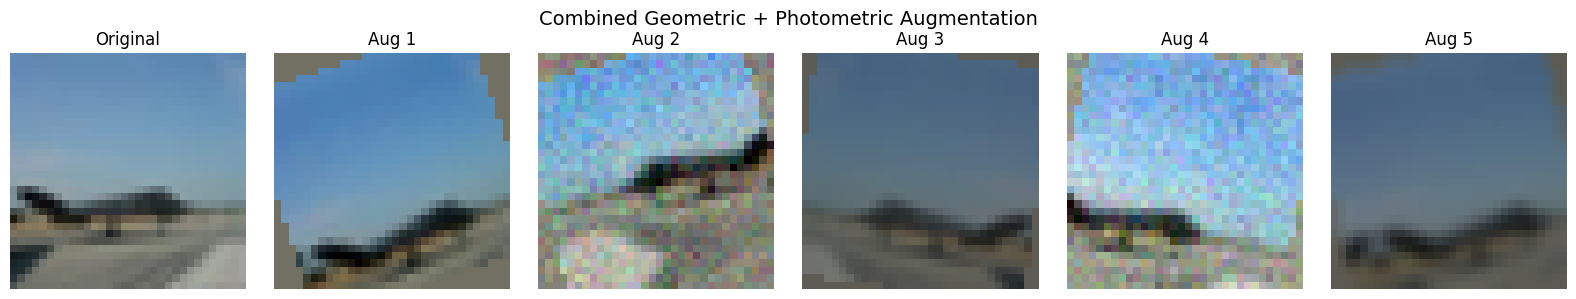

Combined augmentation visualization complete!


In [29]:

import matplotlib.pyplot as plt
from torchvision import transforms

# Display training augmentations without normalization
combined_display_transform = transforms.Compose([
    transforms.RandomCrop(
        32, padding=4, padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    ),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=3,
            sigma=(0.1, 1.0)
        )
    ], p=0.4),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.05, p=0.5),
    transforms.ToPILImage()
])

# Use an original image from training only
sample_index = train_indices[0]
original_image, original_label = train_full[sample_index]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))

axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(5):
    augmented = combined_display_transform(original_image)
    axes[i+1].imshow(augmented)
    axes[i+1].set_title(f"Aug {i+1}")
    axes[i+1].axis("off")

fig.suptitle(
    "Combined Geometric + Photometric Augmentation",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Combined augmentation visualization complete!")


In [30]:

import os
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

os.makedirs("experiment_results", exist_ok=True)

def run_experiment(name, train_data, seed=42, epochs=60):

    # Seed before model initialization
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model, optimizer = make_fresh_model(seed)
    criterion = nn.CrossEntropyLoss()

    # Seed workers for reproducible augmentation
    def seed_worker(worker_id):
        worker_seed = torch.initial_seed() % (2**32)
        np.random.seed(worker_seed)
        random.seed(worker_seed)

    train_loader_run = DataLoader(
        train_data,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        worker_init_fn=seed_worker,
        num_workers=2
    )

    val_loader_run = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    history = initialize_history()
    best_acc = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    start = time.time()

    for epoch in range(epochs):

        tr_loss, tr_acc = train_one_epoch(
            model, train_loader_run,
            optimizer, criterion, device
        )

        vl_loss, vl_acc = validate(
            model, val_loader_run,
            criterion, device
        )

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(vl_loss)
        history["val_acc"].append(vl_acc)

        if (vl_acc > best_acc or
            (vl_acc == best_acc and vl_loss < best_loss)):
            best_acc = vl_acc
            best_loss = vl_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 10 == 0:
            print(
                f"{name} | Seed {seed} | "
                f"Epoch {epoch+1}/{epochs} | "
                f"Train: {tr_acc:.2f}% | "
                f"Val: {vl_acc:.2f}%"
            )

    duration = time.time() - start

    checkpoint_path = (
        f"experiment_results/{name}_seed{seed}.pth"
    )

    torch.save({
        "model_state_dict": best_state,
        "history": history,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_acc,
        "best_val_loss": best_loss,
        "split_seed": SPLIT_SEED,
        "train_indices": train_indices.tolist(),
        "val_indices": val_indices.tolist()
    }, checkpoint_path)

    print("\n========== EXPERIMENT COMPLETE ==========")
    print("Configuration:", name)
    print("Seed:", seed)
    print("Best epoch:", best_epoch)
    print(f"Best validation accuracy: {best_acc:.2f}%")
    print(f"Best validation loss: {best_loss:.4f}")
    print(f"Duration: {duration/60:.2f} minutes")
    print("Saved:", checkpoint_path)

    return {
        "name": name,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_loss": best_loss,
        "duration": duration,
        "history": history,
        "checkpoint": checkpoint_path
    }


print("Reusable experiment runner created successfully!")


Reusable experiment runner created successfully!


In [31]:

# Combined geometric + photometric experiment
# Seed 42, maximum 60 epochs

combined_result = run_experiment(
    name="combined",
    train_data=combined_train_dataset,
    seed=42,
    epochs=60
)

print("\n========== COMPARISON ==========")

print("Baseline:", f"{best_val_accuracy:.2f}%")
print("Geometric:", f"{geo_best_val_acc:.2f}%")
print("Photometric:", f"{photo_best_val_acc:.2f}%")
print("Combined:", f"{combined_result['val_accuracy']:.2f}%")

difference = (
    combined_result["val_accuracy"] - best_val_accuracy
)

print(
    "Combined vs Baseline:",
    f"{difference:+.2f} percentage points"
)


combined | Seed 42 | Epoch 10/60 | Train: 29.25% | Val: 23.00%
combined | Seed 42 | Epoch 20/60 | Train: 35.75% | Val: 42.00%
combined | Seed 42 | Epoch 30/60 | Train: 45.00% | Val: 35.00%
combined | Seed 42 | Epoch 40/60 | Train: 46.50% | Val: 41.00%
combined | Seed 42 | Epoch 50/60 | Train: 53.25% | Val: 42.00%
combined | Seed 42 | Epoch 60/60 | Train: 56.00% | Val: 45.00%

========== EXPERIMENT COMPLETE ==========
Configuration: combined
Seed: 42
Best epoch: 25
Best validation accuracy: 47.00%
Best validation loss: 1.6786
Duration: 0.86 minutes
Saved: experiment_results/combined_seed42.pth

========== COMPARISON ==========
Baseline: 50.00%
Geometric: 50.00%
Photometric: 45.00%
Combined: 47.00%
Combined vs Baseline: -3.00 percentage points


In [32]:

from torchvision import transforms

# Combined augmentation + Random Erasing
cutout_transform = transforms.Compose([
    transforms.RandomCrop(
        32, padding=4, padding_mode="reflect"
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    ),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(3, sigma=(0.1, 1.0))
    ], p=0.4),

    transforms.ToTensor(),
    AddGaussianNoise(std=0.05, p=0.5),

    # Occlusion applied to training images only
    transforms.RandomErasing(
        p=0.5,
        scale=(0.15, 0.25),
        ratio=(0.5, 2.0),
        value="random"
    ),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

cutout_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=cutout_transform
)

cutout_train_dataset = Subset(
    cutout_full_dataset,
    train_indices.tolist()
)

print("Cutout training images:", len(cutout_train_dataset))
print("Validation images:", len(val_dataset))
print("Random Erasing probability: 0.5")
print("Erased area range: 15%-25%")
print("Cutout augmentation ready!")


Cutout training images: 400
Validation images: 100
Random Erasing probability: 0.5
Erased area range: 15%-25%
Cutout augmentation ready!


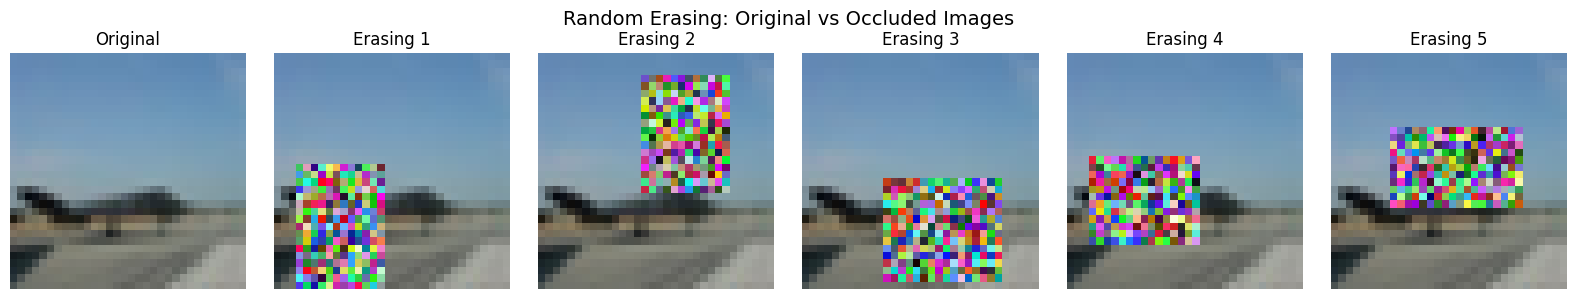

Random Erasing visualization complete!
Training erase probability remains 0.5


In [33]:

import matplotlib.pyplot as plt
from torchvision import transforms

# Visualization only: always apply Random Erasing
cutout_display_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.RandomErasing(
        p=1.0,
        scale=(0.15, 0.25),
        ratio=(0.5, 2.0),
        value="random"
    ),

    transforms.ToPILImage()
])

# Same airplane from training dataset
sample_index = train_indices[0]
original_image, original_label = train_full[sample_index]

fig, axes = plt.subplots(1, 6, figsize=(16, 3))

axes[0].imshow(original_image)
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(5):
    augmented = cutout_display_transform(original_image)

    axes[i + 1].imshow(augmented)
    axes[i + 1].set_title(f"Erasing {i+1}")
    axes[i + 1].axis("off")

fig.suptitle(
    "Random Erasing: Original vs Occluded Images",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Random Erasing visualization complete!")
print("Training erase probability remains 0.5")


In [34]:

# Experiment 5: Combined + Random Erasing
# Seed 42, 60 epochs

cutout_result = run_experiment(
    name="combined_cutout",
    train_data=cutout_train_dataset,
    seed=42,
    epochs=60
)

# Compare validation results
results_so_far = {
    "Baseline": best_val_accuracy,
    "Geometric": geo_best_val_acc,
    "Photometric": photo_best_val_acc,
    "Combined": combined_result["val_accuracy"],
    "Combined + Cutout": cutout_result["val_accuracy"]
}

print("\n========== VALIDATION COMPARISON ==========")

for name, accuracy in results_so_far.items():
    print(f"{name}: {accuracy:.2f}%")

print("\nBest configuration so far:")
best_name = max(results_so_far, key=results_so_far.get)

print(best_name, f"{results_so_far[best_name]:.2f}%")


combined_cutout | Seed 42 | Epoch 10/60 | Train: 27.25% | Val: 21.00%
combined_cutout | Seed 42 | Epoch 20/60 | Train: 35.75% | Val: 33.00%
combined_cutout | Seed 42 | Epoch 30/60 | Train: 40.00% | Val: 30.00%
combined_cutout | Seed 42 | Epoch 40/60 | Train: 41.25% | Val: 36.00%
combined_cutout | Seed 42 | Epoch 50/60 | Train: 39.25% | Val: 34.00%
combined_cutout | Seed 42 | Epoch 60/60 | Train: 43.00% | Val: 33.00%

========== EXPERIMENT COMPLETE ==========
Configuration: combined_cutout
Seed: 42
Best epoch: 27
Best validation accuracy: 40.00%
Best validation loss: 1.7333
Duration: 0.91 minutes
Saved: experiment_results/combined_cutout_seed42.pth

========== VALIDATION COMPARISON ==========
Baseline: 50.00%
Geometric: 50.00%
Photometric: 45.00%
Combined: 47.00%
Combined + Cutout: 40.00%

Best configuration so far:
Baseline 50.00%


In [35]:

import numpy as np
import torch
import torch.nn.functional as F

def mixup_batch(images, labels, alpha=0.2):
    if alpha <= 0:
        raise ValueError("alpha must be positive")

    lam = np.random.beta(alpha, alpha)

    permutation = torch.randperm(
        images.size(0),
        device=images.device
    )

    mixed_images = (
        lam * images
        + (1 - lam) * images[permutation]
    )

    labels_a = labels
    labels_b = labels[permutation]

    return mixed_images, labels_a, labels_b, lam


def mixup_loss(
    predictions,
    labels_a,
    labels_b,
    lam,
    smoothing=0.05
):
    loss_a = F.cross_entropy(
        predictions,
        labels_a,
        label_smoothing=smoothing
    )

    loss_b = F.cross_entropy(
        predictions,
        labels_b,
        label_smoothing=smoothing
    )

    return lam * loss_a + (1 - lam) * loss_b


# Test using dummy tensors only
dummy_images = torch.randn(4, 3, 32, 32)
dummy_labels = torch.tensor([0, 1, 2, 3])

mixed, ya, yb, lam = mixup_batch(
    dummy_images,
    dummy_labels
)

dummy_predictions = torch.randn(4, 10)

test_loss = mixup_loss(
    dummy_predictions,
    ya,
    yb,
    lam
)

print("Original shape:", dummy_images.shape)
print("Mixed shape:", mixed.shape)
print("Lambda:", round(lam, 4))
print("Mixup loss:", round(test_loss.item(), 4))
print("Mixup implementation ready!")


Original shape: torch.Size([4, 3, 32, 32])
Mixed shape: torch.Size([4, 3, 32, 32])
Lambda: 0.0094
Mixup loss: 3.041
Mixup implementation ready!


In [36]:

def train_one_epoch_mixup(
    model,
    loader,
    optimizer,
    device,
    alpha=0.2,
    smoothing=0.05
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Apply Mixup to training batch
        mixed_images, labels_a, labels_b, lam = mixup_batch(
            images,
            labels,
            alpha=alpha
        )

        optimizer.zero_grad()

        # Forward pass using mixed images
        outputs = model(mixed_images)

        # Mixup loss with label smoothing
        loss = mixup_loss(
            outputs,
            labels_a,
            labels_b,
            lam,
            smoothing=smoothing
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        # Weighted training accuracy
        predictions = outputs.argmax(dim=1)

        correct += (
            lam * (predictions == labels_a).sum().item()
            + (1 - lam) * (predictions == labels_b).sum().item()
        )

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Mixup training function created successfully!")
print("Mixup alpha: 0.2")
print("Label smoothing: 0.05")


Mixup training function created successfully!
Mixup alpha: 0.2
Label smoothing: 0.05


In [37]:

import os
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

def run_experiment_v2(
    name,
    train_data,
    seed=42,
    epochs=60,
    use_mixup=False,
    mixup_alpha=0.2,
    label_smoothing=0.05
):

    # Reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Fresh model and optimizer
    model, optimizer = make_fresh_model(seed)

    criterion = nn.CrossEntropyLoss()

    # Create independent DataLoaders
    train_loader_run = DataLoader(
        train_data,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=2
    )

    val_loader_run = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    history = initialize_history()

    best_acc = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    start = time.time()

    for epoch in range(epochs):

        # Choose training procedure
        if use_mixup:
            tr_loss, tr_acc = train_one_epoch_mixup(
                model,
                train_loader_run,
                optimizer,
                device,
                alpha=mixup_alpha,
                smoothing=label_smoothing
            )
        else:
            tr_loss, tr_acc = train_one_epoch(
                model,
                train_loader_run,
                optimizer,
                criterion,
                device
            )

        # Always validate on clean validation data
        vl_loss, vl_acc = validate(
            model,
            val_loader_run,
            criterion,
            device
        )

        # Save metrics
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(vl_loss)
        history["val_acc"].append(vl_acc)

        # Best checkpoint by validation accuracy
        if (
            vl_acc > best_acc
            or (
                vl_acc == best_acc
                and vl_loss < best_loss
            )
        ):
            best_acc = vl_acc
            best_loss = vl_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        if (epoch + 1) % 10 == 0:
            print(
                f"{name} | Seed {seed} | "
                f"Epoch {epoch+1}/{epochs} | "
                f"Train: {tr_acc:.2f}% | "
                f"Val: {vl_acc:.2f}%"
            )

    duration = time.time() - start

    os.makedirs("experiment_results", exist_ok=True)

    checkpoint_path = (
        f"experiment_results/{name}_seed{seed}.pth"
    )

    torch.save({
        "model_state_dict": best_state,
        "history": history,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_acc,
        "best_val_loss": best_loss,
        "split_seed": SPLIT_SEED,
        "train_indices": train_indices.tolist(),
        "val_indices": val_indices.tolist(),
        "use_mixup": use_mixup,
        "mixup_alpha": mixup_alpha if use_mixup else None,
        "label_smoothing": label_smoothing if use_mixup else 0.0
    }, checkpoint_path)

    print("\n========== EXPERIMENT COMPLETE ==========")
    print("Configuration:", name)
    print("Seed:", seed)
    print("Mixup enabled:", use_mixup)
    print("Best epoch:", best_epoch)
    print(f"Best validation accuracy: {best_acc:.2f}%")
    print(f"Best validation loss: {best_loss:.4f}")
    print(f"Duration: {duration/60:.2f} minutes")
    print("Saved:", checkpoint_path)

    return {
        "name": name,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_loss": best_loss,
        "duration": duration,
        "history": history,
        "checkpoint": checkpoint_path
    }


print("Experiment Runner V2 created successfully!")
print("Normal training supported: True")
print("Mixup training supported: True")


Experiment Runner V2 created successfully!
Normal training supported: True
Mixup training supported: True


In [38]:

# Experiment 6: Combined + Cutout + Mixup
# Fresh model, seed 42, 60 epochs

mixup_result = run_experiment_v2(
    name="combined_cutout_mixup",
    train_data=cutout_train_dataset,
    seed=42,
    epochs=60,
    use_mixup=True,
    mixup_alpha=0.2,
    label_smoothing=0.05
)

print("\n========== MIXUP COMPARISON ==========")

print(f"Baseline: {best_val_accuracy:.2f}%")
print(f"Geometric: {geo_best_val_acc:.2f}%")
print(f"Photometric: {photo_best_val_acc:.2f}%")
print(f"Combined: {combined_result['val_accuracy']:.2f}%")
print(f"Cutout: {cutout_result['val_accuracy']:.2f}%")
print(f"Mixup: {mixup_result['val_accuracy']:.2f}%")

print(
    "Mixup vs Cutout:",
    f"{mixup_result['val_accuracy'] - cutout_result['val_accuracy']:+.2f} pp"
)


combined_cutout_mixup | Seed 42 | Epoch 10/60 | Train: 22.76% | Val: 26.00%
combined_cutout_mixup | Seed 42 | Epoch 20/60 | Train: 31.64% | Val: 33.00%
combined_cutout_mixup | Seed 42 | Epoch 30/60 | Train: 31.51% | Val: 31.00%
combined_cutout_mixup | Seed 42 | Epoch 40/60 | Train: 39.69% | Val: 31.00%
combined_cutout_mixup | Seed 42 | Epoch 50/60 | Train: 38.09% | Val: 37.00%
combined_cutout_mixup | Seed 42 | Epoch 60/60 | Train: 40.32% | Val: 37.00%

========== EXPERIMENT COMPLETE ==========
Configuration: combined_cutout_mixup
Seed: 42
Mixup enabled: True
Best epoch: 48
Best validation accuracy: 39.00%
Best validation loss: 1.6964
Duration: 0.95 minutes
Saved: experiment_results/combined_cutout_mixup_seed42.pth

========== MIXUP COMPARISON ==========
Baseline: 50.00%
Geometric: 50.00%
Photometric: 45.00%
Combined: 47.00%
Cutout: 40.00%
Mixup: 39.00%
Mixup vs Cutout: -1.00 pp


In [39]:

from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import Subset

# Moderate augmentation for final candidate
final_transform = transforms.Compose([
    transforms.RandomCrop(
        32,
        padding=2,
        padding_mode="reflect"
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=15,
        interpolation=InterpolationMode.BILINEAR,
        fill=(125, 123, 114)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.RandomErasing(
        p=0.25,
        scale=(0.08, 0.18),
        ratio=(0.5, 2.0),
        value="random"
    ),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

final_full_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=final_transform
)

final_train_dataset = Subset(
    final_full_dataset,
    train_indices.tolist()
)

print("Final training images:", len(final_train_dataset))
print("Validation images:", len(val_dataset))
print("Final augmentation ready!")


Final training images: 400
Validation images: 100
Final augmentation ready!


In [40]:

import os
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import DataLoader

def run_final_experiment(
    name,
    train_data,
    seed=42,
    epochs=60
):
    if not 1 <= epochs <= 60:
        raise ValueError("Epochs must be between 1 and 60")

    # Reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Fresh model and optimizer
    model, optimizer = make_fresh_model(seed)
    criterion = nn.CrossEntropyLoss()

    # Cosine learning rate scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
        eta_min=1e-5
    )

    # Seed DataLoader workers
    def seed_worker(worker_id):
        worker_seed = torch.initial_seed() % (2**32)
        np.random.seed(worker_seed)
        random.seed(worker_seed)

    train_loader_run = DataLoader(
        train_data,
        batch_size=32,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        worker_init_fn=seed_worker,
        num_workers=2
    )

    val_loader_run = DataLoader(
        val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    history = initialize_history()
    history["learning_rate"] = []

    best_acc = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    start_time = time.time()

    for epoch in range(epochs):

        # Record current learning rate
        current_lr = optimizer.param_groups[0]["lr"]
        history["learning_rate"].append(current_lr)

        # Training
        tr_loss, tr_acc = train_one_epoch(
            model,
            train_loader_run,
            optimizer,
            criterion,
            device
        )

        # Clean validation
        vl_loss, vl_acc = validate(
            model,
            val_loader_run,
            criterion,
            device
        )

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(vl_loss)
        history["val_acc"].append(vl_acc)

        # Best checkpoint based on validation only
        if (
            vl_acc > best_acc
            or (
                vl_acc == best_acc
                and vl_loss < best_loss
            )
        ):
            best_acc = vl_acc
            best_loss = vl_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        # Update LR after each epoch
        scheduler.step()

        if (epoch + 1) % 10 == 0:
            print(
                f"{name} | Seed {seed} | "
                f"Epoch {epoch+1}/{epochs} | "
                f"Train: {tr_acc:.2f}% | "
                f"Val: {vl_acc:.2f}% | "
                f"LR: {current_lr:.6f}"
            )

    duration = time.time() - start_time

    os.makedirs("experiment_results", exist_ok=True)

    checkpoint_path = (
        f"experiment_results/{name}_seed{seed}.pth"
    )

    torch.save({
        "model_state_dict": best_state,
        "history": history,
        "seed": seed,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_acc,
        "best_val_loss": best_loss,
        "split_seed": SPLIT_SEED,
        "train_indices": train_indices.tolist(),
        "val_indices": val_indices.tolist(),
        "scheduler": "CosineAnnealingLR",
        "initial_lr": 0.001,
        "min_lr": 1e-5,
        "epochs": epochs,
        "augmentation": "Moderate geometric + photometric + erasing"
    }, checkpoint_path)

    print("\n========== FINAL CANDIDATE SUMMARY ==========")
    print("Configuration:", name)
    print("Seed:", seed)
    print("Best epoch:", best_epoch)
    print(f"Best validation accuracy: {best_acc:.2f}%")
    print(f"Best validation loss: {best_loss:.4f}")
    print(f"Training duration: {duration/60:.2f} minutes")
    print("Saved:", checkpoint_path)

    return {
        "name": name,
        "seed": seed,
        "best_epoch": best_epoch,
        "val_accuracy": best_acc,
        "val_loss": best_loss,
        "duration": duration,
        "history": history,
        "checkpoint": checkpoint_path
    }


print("Final experiment runner created successfully!")
print("Scheduler: CosineAnnealingLR")
print("Initial LR: 0.001")
print("Minimum LR: 0.00001")
print("Maximum epochs: 60")


Final experiment runner created successfully!
Scheduler: CosineAnnealingLR
Initial LR: 0.001
Minimum LR: 0.00001
Maximum epochs: 60


In [41]:

# Experiment 7: Final candidate
# Moderate augmentation + Cosine LR Scheduler
# Seed 42, maximum 60 epochs

final_result = run_final_experiment(
    name="final_candidate",
    train_data=final_train_dataset,
    seed=42,
    epochs=60
)

# Compare with previous configurations
validation_results = {
    "Baseline": best_val_accuracy,
    "Geometric": geo_best_val_acc,
    "Photometric": photo_best_val_acc,
    "Combined": combined_result["val_accuracy"],
    "Cutout": cutout_result["val_accuracy"],
    "Mixup": mixup_result["val_accuracy"],
    "Final Candidate": final_result["val_accuracy"]
}

print("\n========== SEED 42 COMPARISON ==========")

for name, accuracy in validation_results.items():
    print(f"{name}: {accuracy:.2f}%")

best_configuration = max(
    validation_results,
    key=validation_results.get
)

print("\nBest configuration so far:")
print(
    best_configuration,
    f"{validation_results[best_configuration]:.2f}%"
)

print(
    "Final candidate vs baseline:",
    f"{final_result['val_accuracy'] - best_val_accuracy:+.2f} pp"
)


final_candidate | Seed 42 | Epoch 10/60 | Train: 33.75% | Val: 25.00% | LR: 0.000946
final_candidate | Seed 42 | Epoch 20/60 | Train: 46.25% | Val: 31.00% | LR: 0.000775
final_candidate | Seed 42 | Epoch 30/60 | Train: 50.50% | Val: 36.00% | LR: 0.000531
final_candidate | Seed 42 | Epoch 40/60 | Train: 56.50% | Val: 39.00% | LR: 0.000280
final_candidate | Seed 42 | Epoch 50/60 | Train: 58.25% | Val: 39.00% | LR: 0.000090
final_candidate | Seed 42 | Epoch 60/60 | Train: 61.00% | Val: 40.00% | LR: 0.000011

========== FINAL CANDIDATE SUMMARY ==========
Configuration: final_candidate
Seed: 42
Best epoch: 43
Best validation accuracy: 42.00%
Best validation loss: 1.6142
Training duration: 0.82 minutes
Saved: experiment_results/final_candidate_seed42.pth

========== SEED 42 COMPARISON ==========
Baseline: 50.00%
Geometric: 50.00%
Photometric: 45.00%
Combined: 47.00%
Cutout: 40.00%
Mixup: 39.00%
Final Candidate: 42.00%

Best configuration so far:
Baseline 50.00%
Final candidate vs baseline: -

In [42]:

# Remaining seeds for reproducibility
REMAINING_SEEDS = [123, 2026]

# Seven assignment configurations
experiment_configs = {
    "baseline": train_dataset,
    "geometric": geometric_train_dataset,
    "photometric": photo_train_dataset,
    "combined": combined_train_dataset,
    "combined_cutout": cutout_train_dataset,
    "combined_cutout_mixup": cutout_train_dataset,
    "final_candidate": final_train_dataset
}

print("========== MULTI-SEED PLAN ==========")
print("Remaining seeds:", REMAINING_SEEDS)
print("Configurations:", len(experiment_configs))

for name, dataset in experiment_configs.items():
    print(f"{name}: {len(dataset)} training images")

print(
    "Total remaining runs:",
    len(REMAINING_SEEDS) * len(experiment_configs)
)

print("Multi-seed configuration ready!")


========== MULTI-SEED PLAN ==========
Remaining seeds: [123, 2026]
Configurations: 7
baseline: 400 training images
geometric: 400 training images
photometric: 400 training images
combined: 400 training images
combined_cutout: 400 training images
combined_cutout_mixup: 400 training images
final_candidate: 400 training images
Total remaining runs: 14
Multi-seed configuration ready!


In [43]:

import os
import pandas as pd
import torch

os.makedirs("experiment_results", exist_ok=True)

# Only the two remaining seeds
REMAINING_SEEDS = [123, 2026]

all_new_results = []

# Configure experiment runners
for seed in REMAINING_SEEDS:

    print("\n" + "=" * 55)
    print(f"STARTING EXPERIMENTS FOR SEED {seed}")
    print("=" * 55)

    for config_name, dataset in experiment_configs.items():

        checkpoint_path = (
            f"experiment_results/"
            f"{config_name}_seed{seed}.pth"
        )

        # Avoid repeating a completed experiment
        if os.path.exists(checkpoint_path):

            print(
                f"Skipping {config_name}, seed {seed}: "
                "checkpoint already exists."
            )

            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=True
            )

            result = {
                "name": config_name,
                "seed": seed,
                "best_epoch": checkpoint["best_epoch"],
                "val_accuracy": checkpoint["best_val_accuracy"],
                "val_loss": checkpoint["best_val_loss"],
                "checkpoint": checkpoint_path
            }

        elif config_name == "final_candidate":

            result = run_final_experiment(
                name=config_name,
                train_data=dataset,
                seed=seed,
                epochs=60
            )

        else:

            result = run_experiment_v2(
                name=config_name,
                train_data=dataset,
                seed=seed,
                epochs=60,
                use_mixup=(
                    config_name == "combined_cutout_mixup"
                ),
                mixup_alpha=0.2,
                label_smoothing=0.05
            )

        all_new_results.append(result)

        # Save incremental CSV after each experiment
        results_df = pd.DataFrame([
            {
                "configuration": r["name"],
                "seed": r["seed"],
                "best_epoch": r["best_epoch"],
                "val_accuracy": r["val_accuracy"],
                "val_loss": r["val_loss"],
                "checkpoint": r["checkpoint"]
            }
            for r in all_new_results
        ])

        results_df.to_csv(
            "experiment_results/remaining_seeds.csv",
            index=False
        )

        print(
            f"Progress: {len(all_new_results)}/14 "
            "experiments processed"
        )

print("\n========== ALL REMAINING RUNS COMPLETE ==========")

print(results_df[
    ["configuration", "seed", "best_epoch", "val_accuracy"]
].to_string(index=False))

print("\nResults saved to:")
print("experiment_results/remaining_seeds.csv")



STARTING EXPERIMENTS FOR SEED 123
baseline | Seed 123 | Epoch 10/60 | Train: 47.50% | Val: 38.00%
baseline | Seed 123 | Epoch 20/60 | Train: 71.00% | Val: 35.00%
baseline | Seed 123 | Epoch 30/60 | Train: 88.75% | Val: 37.00%
baseline | Seed 123 | Epoch 40/60 | Train: 94.50% | Val: 45.00%
baseline | Seed 123 | Epoch 50/60 | Train: 97.25% | Val: 45.00%
baseline | Seed 123 | Epoch 60/60 | Train: 99.50% | Val: 45.00%

========== EXPERIMENT COMPLETE ==========
Configuration: baseline
Seed: 123
Mixup enabled: False
Best epoch: 44
Best validation accuracy: 50.00%
Best validation loss: 1.5416
Duration: 0.60 minutes
Saved: experiment_results/baseline_seed123.pth
Progress: 1/14 experiments processed
geometric | Seed 123 | Epoch 10/60 | Train: 37.25% | Val: 33.00%
geometric | Seed 123 | Epoch 20/60 | Train: 47.00% | Val: 38.00%
geometric | Seed 123 | Epoch 30/60 | Train: 58.25% | Val: 39.00%
geometric | Seed 123 | Epoch 40/60 | Train: 60.00% | Val: 38.00%
geometric | Seed 123 | Epoch 50/60 | Tr

In [44]:

import pandas as pd

# Latest seed 42 validation results
seed42_results = {
    "baseline": 50.0,
    "geometric": 50.0,
    "photometric": 45.0,
    "combined": 47.0,
    "combined_cutout": 40.0,
    "combined_cutout_mixup": 39.0,
    "final_candidate": 42.0
}

# Load completed seeds 123 and 2026
remaining_df = pd.read_csv(
    "experiment_results/remaining_seeds.csv"
)

seed42_df = pd.DataFrame([
    {
        "configuration": name,
        "seed": 42,
        "val_accuracy": accuracy
    }
    for name, accuracy in seed42_results.items()
])

# Combine all three seeds
all_results_df = pd.concat(
    [
        seed42_df,
        remaining_df[
            ["configuration", "seed", "val_accuracy"]
        ]
    ],
    ignore_index=True
)

assert len(all_results_df) == 21
assert not all_results_df.duplicated(
    ["configuration", "seed"]
).any()

# Sample standard deviation (ddof=1)
summary_df = all_results_df.groupby(
    "configuration"
)["val_accuracy"].agg(
    mean="mean",
    std="std",
    count="count"
).reset_index()

summary_df["Mean ± Std"] = summary_df.apply(
    lambda r: f"{r['mean']:.2f} ± {r['std']:.2f}%",
    axis=1
)

summary_df = summary_df.sort_values(
    "mean",
    ascending=False
)

print("====== THREE-SEED VALIDATION RESULTS ======")
print(
    summary_df[
        ["configuration", "Mean ± Std", "count"]
    ].to_string(index=False)
)

print("\nBest mean validation configuration:")
print(summary_df.iloc[0]["configuration"])

# Save results for report
all_results_df.to_csv(
    "experiment_results/all_21_validation_results.csv",
    index=False
)

summary_df.to_csv(
    "experiment_results/validation_summary.csv",
    index=False
)

print("\nCSV files saved successfully!")


====== THREE-SEED VALIDATION RESULTS ======
        configuration    Mean ± Std  count
             baseline 48.67 ± 2.31%      3
            geometric 48.67 ± 3.21%      3
          photometric 47.67 ± 2.52%      3
             combined 46.00 ± 1.00%      3
      final_candidate 45.33 ± 3.51%      3
      combined_cutout 43.00 ± 3.00%      3
combined_cutout_mixup 42.00 ± 3.61%      3

Best mean validation configuration:
baseline

CSV files saved successfully!


In [45]:

from google.colab import drive
import os
import shutil
import zipfile
from datetime import datetime

# Mount Google Drive
drive.mount("/content/drive")

# Create backup folder
backup_folder = (
    "/content/drive/MyDrive/"
    "DL_Assignment2_Backup_23F_0632"
)

os.makedirs(backup_folder, exist_ok=True)

# Create ZIP backup
backup_zip = os.path.join(
    backup_folder,
    "Section_B_Experiments_Backup.zip"
)

with zipfile.ZipFile(
    backup_zip, "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    # All experiment checkpoints and CSV files
    if os.path.isdir("experiment_results"):
        for root, dirs, files in os.walk("experiment_results"):
            for filename in files:
                path = os.path.join(root, filename)
                zipf.write(path, arcname=path)

    # Previous standalone checkpoints and graphs
    for filename in os.listdir("."):
        if filename.endswith((".pth", ".png", ".csv")):
            if os.path.isfile(filename):
                zipf.write(filename)

print("========== BACKUP COMPLETE ==========")
print("Google Drive folder:", backup_folder)
print("ZIP file:", backup_zip)
print(
    "Backup size:",
    round(os.path.getsize(backup_zip) / (1024**2), 2),
    "MB"
)


Mounted at /content/drive
========== BACKUP COMPLETE ==========
Google Drive folder: /content/drive/MyDrive/DL_Assignment2_Backup_23F_0632
ZIP file: /content/drive/MyDrive/DL_Assignment2_Backup_23F_0632/Section_B_Experiments_Backup.zip
Backup size: 7.39 MB


In [46]:

import zipfile
import os

backup_zip = (
    "/content/drive/MyDrive/"
    "DL_Assignment2_Backup_23F_0632/"
    "Section_B_Experiments_Backup.zip"
)

with zipfile.ZipFile(backup_zip, "r") as z:
    files = z.namelist()
    corrupt_file = z.testzip()

checkpoint_files = [
    f for f in files
    if f.endswith(".pth")
]

csv_files = [
    f for f in files
    if f.endswith(".csv")
]

image_files = [
    f for f in files
    if f.endswith(".png")
]

print("========== BACKUP VERIFICATION ==========")
print("ZIP exists:", os.path.exists(backup_zip))
print("ZIP integrity:", "PASS" if corrupt_file is None else "FAIL")
print("Total checkpoints:", len(checkpoint_files))
print("CSV files:", len(csv_files))
print("Graph images:", len(image_files))

required_configs = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

seeds = [42, 123, 2026]

missing = []

for config in required_configs:
    for seed in seeds:
        expected = (
            f"experiment_results/{config}_seed{seed}.pth"
        )
        if expected not in files:
            missing.append(expected)

print("Required experiment checkpoints found:", 21 - len(missing))
print("Missing required checkpoints:", len(missing))

if missing:
    print("Missing files:")
    for f in missing:
        print(" -", f)
else:
    print("All 21 required checkpoints are backed up!")

print("Verification complete!")


========== BACKUP VERIFICATION ==========
ZIP exists: True
ZIP integrity: PASS
Total checkpoints: 21
CSV files: 3
Graph images: 3
Required experiment checkpoints found: 18
Missing required checkpoints: 3
Missing files:
 - experiment_results/baseline_seed42.pth
 - experiment_results/geometric_seed42.pth
 - experiment_results/photometric_seed42.pth
Verification complete!


In [47]:

import os
import shutil
import zipfile

folder = "experiment_results"

checkpoint_mapping = {
    "baseline": "baseline_seed42_best.pth",
    "geometric": "geometric_seed42_best.pth",
    "photometric": "photometric_seed42_best.pth"
}

print("========== CHECKPOINT RECOVERY ==========")

for config, old_name in checkpoint_mapping.items():

    new_path = f"{folder}/{config}_seed42.pth"

    possible_sources = [
        old_name,
        f"{folder}/{old_name}"
    ]

    if os.path.exists(new_path):
        print(config, "ALREADY EXISTS")
        continue

    source = next(
        (p for p in possible_sources if os.path.exists(p)),
        None
    )

    if source is not None:
        shutil.copy2(source, new_path)
        print(config, "RECOVERED:", new_path)
    else:
        print(config, "SOURCE NOT FOUND")

print("\n========== VERIFICATION ==========")

for config in checkpoint_mapping:
    path = f"{folder}/{config}_seed42.pth"
    print(config, os.path.exists(path))


========== CHECKPOINT RECOVERY ==========
baseline RECOVERED: experiment_results/baseline_seed42.pth
geometric RECOVERED: experiment_results/geometric_seed42.pth
photometric RECOVERED: experiment_results/photometric_seed42.pth

========== VERIFICATION ==========
baseline True
geometric True
photometric True


In [48]:

import os
import torch

configs = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

seeds = [42, 123, 2026]

# Latest known seed-42 validation results
expected_seed42 = {
    "baseline": 50.0,
    "geometric": 50.0,
    "photometric": 45.0,
    "combined": 47.0,
    "combined_cutout": 40.0,
    "combined_cutout_mixup": 39.0,
    "final_candidate": 42.0
}

verification_rows = []
problems = []

for config in configs:
    for seed in seeds:
        path = f"experiment_results/{config}_seed{seed}.pth"

        if not os.path.isfile(path):
            problems.append(f"Missing: {path}")
            continue

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        saved_seed = int(checkpoint["seed"])
        saved_accuracy = float(
            checkpoint["best_val_accuracy"]
        )
        best_epoch = int(checkpoint["best_epoch"])

        # Check model weights and metadata
        if saved_seed != seed:
            problems.append(f"Seed mismatch: {path}")

        if not (1 <= best_epoch <= 60):
            problems.append(f"Invalid epoch: {path}")

        if not checkpoint.get("model_state_dict"):
            problems.append(f"Missing model weights: {path}")

        if seed == 42:
            expected = expected_seed42[config]

            if abs(saved_accuracy - expected) > 0.001:
                problems.append(
                    f"Accuracy mismatch: {config} "
                    f"saved={saved_accuracy}, expected={expected}"
                )

        verification_rows.append({
            "configuration": config,
            "seed": seed,
            "best_epoch": best_epoch,
            "validation_accuracy": saved_accuracy
        })

print("========== CHECKPOINT VERIFICATION ==========")
print("Checkpoints verified:", len(verification_rows))
print("Problems found:", len(problems))

if problems:
    for problem in problems:
        print("WARNING:", problem)
else:
    print("All 21 checkpoint metadata checks passed!")

print("\nSeed 42:")
for row in verification_rows:
    if row["seed"] == 42:
        print(
            row["configuration"],
            f"{row['validation_accuracy']:.2f}%",
            "epoch", row["best_epoch"]
        )


========== CHECKPOINT VERIFICATION ==========
Checkpoints verified: 21
Problems found: 0
All 21 checkpoint metadata checks passed!

Seed 42:
baseline 50.00% epoch 37
geometric 50.00% epoch 42
photometric 45.00% epoch 32
combined 47.00% epoch 25
combined_cutout 40.00% epoch 27
combined_cutout_mixup 39.00% epoch 48
final_candidate 42.00% epoch 43


In [49]:

import os
import zipfile
import shutil

# Google Drive backup location
backup_folder = (
    "/content/drive/MyDrive/"
    "DL_Assignment2_Backup_23F_0632"
)

os.makedirs(backup_folder, exist_ok=True)

backup_zip = os.path.join(
    backup_folder,
    "Section_B_Experiments_Backup.zip"
)

temp_zip = os.path.join(
    backup_folder,
    "Section_B_Experiments_Backup_NEW.zip"
)

configs = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

seeds = [42, 123, 2026]

# Confirm all checkpoints exist before rebuilding
required_files = [
    f"experiment_results/{config}_seed{seed}.pth"
    for config in configs
    for seed in seeds
]

missing = [
    path for path in required_files
    if not os.path.isfile(path)
]

if missing:
    raise FileNotFoundError(
        "Missing checkpoints: " + str(missing)
    )

# Build updated backup ZIP
with zipfile.ZipFile(
    temp_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, files in os.walk("experiment_results"):
        for filename in files:
            path = os.path.join(root, filename)
            z.write(path, arcname=path)

    # Include standalone plots/checkpoints
    for filename in os.listdir("."):
        if (
            os.path.isfile(filename)
            and filename.endswith((".png", ".csv", ".pth"))
        ):
            z.write(filename, arcname=filename)

# Verify ZIP before replacing old backup
with zipfile.ZipFile(temp_zip, "r") as z:
    stored_files = set(z.namelist())
    corrupt_file = z.testzip()

    missing_inside = [
        path for path in required_files
        if path not in stored_files
    ]

if corrupt_file is not None or missing_inside:
    raise RuntimeError(
        f"ZIP verification failed: {missing_inside}"
    )

# Replace old backup only after verification succeeds
os.replace(temp_zip, backup_zip)

print("========== UPDATED BACKUP ==========")
print("ZIP integrity: PASS")
print("Required checkpoints: 21/21")
print("Backup file:", backup_zip)
print(
    "Backup size:",
    round(os.path.getsize(backup_zip) / 1024**2, 2),
    "MB"
)
print("Updated Google Drive backup successful!")


========== UPDATED BACKUP ==========
ZIP integrity: PASS
Required checkpoints: 21/21
Backup file: /content/drive/MyDrive/DL_Assignment2_Backup_23F_0632/Section_B_Experiments_Backup.zip
Backup size: 8.32 MB
Updated Google Drive backup successful!


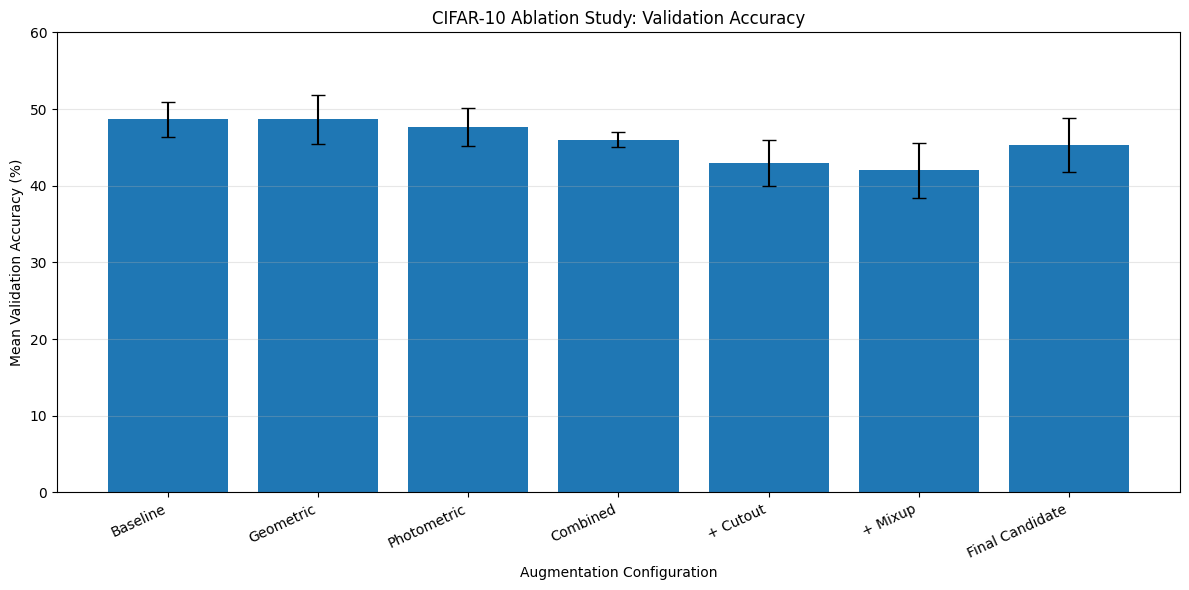

Ablation graph saved successfully!
Configurations: 7
Seeds per configuration: 3


In [50]:

import pandas as pd
import matplotlib.pyplot as plt

# Load saved three-seed summary
summary = pd.read_csv(
    "experiment_results/validation_summary.csv"
)

order = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

labels = [
    "Baseline",
    "Geometric",
    "Photometric",
    "Combined",
    "+ Cutout",
    "+ Mixup",
    "Final Candidate"
]

summary = summary.set_index("configuration").loc[order]

plt.figure(figsize=(12, 6))

plt.bar(
    labels,
    summary["mean"],
    yerr=summary["std"],
    capsize=5
)

plt.title("CIFAR-10 Ablation Study: Validation Accuracy")
plt.xlabel("Augmentation Configuration")
plt.ylabel("Mean Validation Accuracy (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 60)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "experiment_results/ablation_validation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Ablation graph saved successfully!")
print("Configurations:", len(summary))
print("Seeds per configuration:", 3)


In [51]:

import pandas as pd
import json
import os

summary = pd.read_csv(
    "experiment_results/validation_summary.csv"
)

# Select using validation mean,
# then lower standard deviation as tie-breaker
ranked = summary.sort_values(
    by=["mean", "std", "configuration"],
    ascending=[False, True, True]
)

selected = ranked.iloc[0]

selected_config = selected["configuration"]

selection_record = {
    "selected_configuration": selected_config,
    "validation_mean": float(selected["mean"]),
    "validation_std": float(selected["std"]),
    "selection_rule": (
        "Highest 3-seed mean validation accuracy; "
        "lower standard deviation breaks ties"
    ),
    "seeds": [42, 123, 2026],
    "split_seed": 42,
    "test_data_used_for_selection": False
}

os.makedirs("experiment_results", exist_ok=True)

with open(
    "experiment_results/model_selection.json",
    "w"
) as f:
    json.dump(selection_record, f, indent=4)

print("========== MODEL SELECTION ==========")
print("Selected:", selected_config)
print(
    "Validation:",
    f"{selected['mean']:.2f} ± {selected['std']:.2f}%"
)
print("Seeds:", selection_record["seeds"])
print("Test data used for selection: False")
print("Selection saved!")


========== MODEL SELECTION ==========
Selected: baseline
Validation: 48.67 ± 2.31%
Seeds: [42, 123, 2026]
Test data used for selection: False
Selection saved!


In [52]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Clean-test preprocessing: no random augmentation
clean_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Original CIFAR-10 test dataset
clean_test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=clean_test_transform
)

clean_test_loader = DataLoader(
    clean_test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

print("========== CLEAN TEST DATASET ==========")
print("Test images:", len(clean_test_dataset))
print("Test batches:", len(clean_test_loader))
print("Classes:", clean_test_dataset.classes)

# Confirm one batch's shape
images, labels = next(iter(clean_test_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Random augmentation: Disabled")
print("Clean test DataLoader ready!")


========== CLEAN TEST DATASET ==========
Test images: 10000
Test batches: 79
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Batch shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Random augmentation: Disabled
Clean test DataLoader ready!


In [53]:

import os
import torch
import numpy as np
import pandas as pd

TEST_SEEDS = [42, 123, 2026]

clean_results = []

for seed in TEST_SEEDS:

    checkpoint_path = (
        f"experiment_results/baseline_seed{seed}.pth"
    )

    assert os.path.exists(checkpoint_path), (
        f"Checkpoint missing: {checkpoint_path}"
    )

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["seed"] == seed

    # Reconstruct model
    test_model = SmallInceptionCNN().to(device)

    test_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    test_model.eval()

    # Evaluate on all 10,000 clean test images
    test_loss, test_accuracy = validate(
        test_model,
        clean_test_loader,
        nn.CrossEntropyLoss(),
        device
    )

    clean_results.append({
        "seed": seed,
        "best_epoch": checkpoint["best_epoch"],
        "validation_accuracy": checkpoint[
            "best_val_accuracy"
        ],
        "clean_test_accuracy": test_accuracy,
        "clean_test_loss": test_loss
    })

    print(
        f"Seed {seed} | "
        f"Clean Test Accuracy: {test_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f}"
    )

# Calculate mean and sample standard deviation
clean_accuracies = [
    result["clean_test_accuracy"]
    for result in clean_results
]

clean_mean = np.mean(clean_accuracies)
clean_std = np.std(clean_accuracies, ddof=1)

# Save evaluation results
clean_df = pd.DataFrame(clean_results)

clean_df.to_csv(
    "experiment_results/clean_test_results.csv",
    index=False
)

print("\n========== CLEAN TEST SUMMARY ==========")
print("Configuration: Baseline")
print("Test images: 10000")
print("Seeds:", TEST_SEEDS)
print(f"Mean accuracy: {clean_mean:.2f}%")
print(f"Standard deviation: {clean_std:.2f}%")
print(
    f"Final clean-test accuracy: "
    f"{clean_mean:.2f} ± {clean_std:.2f}%"
)
print("Results saved successfully!")


Seed 42 | Clean Test Accuracy: 40.23% | Test Loss: 1.8658
Seed 123 | Clean Test Accuracy: 41.55% | Test Loss: 1.7741
Seed 2026 | Clean Test Accuracy: 42.03% | Test Loss: 1.8326

========== CLEAN TEST SUMMARY ==========
Configuration: Baseline
Test images: 10000
Seeds: [42, 123, 2026]
Mean accuracy: 41.27%
Standard deviation: 0.93%
Final clean-test accuracy: 41.27 ± 0.93%
Results saved successfully!


In [54]:

import os
import torch
import numpy as np
import pandas as pd

CONFIGS = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

SEEDS = [42, 123, 2026]

def evaluate_checkpoint(config, seed, test_loader):
    path = f"experiment_results/{config}_seed{seed}.pth"

    if not os.path.isfile(path):
        raise FileNotFoundError(path)

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model = SmallInceptionCNN().to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    loss, accuracy = validate(
        model,
        test_loader,
        nn.CrossEntropyLoss(),
        device
    )

    return {
        "configuration": config,
        "seed": seed,
        "accuracy": accuracy,
        "loss": loss
    }


print("Evaluation function ready!")
print("Configurations:", len(CONFIGS))
print("Seeds:", SEEDS)
print("Total checkpoints:", len(CONFIGS) * len(SEEDS))
print("No training will be performed.")


Evaluation function ready!
Configurations: 7
Seeds: [42, 123, 2026]
Total checkpoints: 21
No training will be performed.


In [55]:

import pandas as pd
import numpy as np
import os

all_clean_results = []

print("========== CLEAN-TEST EVALUATION ==========")

for config in CONFIGS:
    for seed in SEEDS:

        result = evaluate_checkpoint(
            config=config,
            seed=seed,
            test_loader=clean_test_loader
        )

        all_clean_results.append(result)

        print(
            f"{config:25s} | "
            f"Seed {seed} | "
            f"Accuracy: {result['accuracy']:.2f}%"
        )

# Save individual seed results
all_clean_df = pd.DataFrame(all_clean_results)

all_clean_df.to_csv(
    "experiment_results/all_clean_test_results.csv",
    index=False
)

# Calculate mean and sample standard deviation
clean_summary = (
    all_clean_df.groupby("configuration")["accuracy"]
    .agg(
        mean="mean",
        std="std",
        count="count"
    )
    .reset_index()
)

clean_summary["Mean ± Std"] = clean_summary.apply(
    lambda row: (
        f"{row['mean']:.2f} ± {row['std']:.2f}%"
    ),
    axis=1
)

clean_summary.to_csv(
    "experiment_results/clean_test_summary.csv",
    index=False
)

print("\n========== CLEAN-TEST SUMMARY ==========")

print(
    clean_summary[
        ["configuration", "Mean ± Std", "count"]
    ].to_string(index=False)
)

# Verify each configuration has exactly 3 seeds
assert len(all_clean_df) == 21
assert (clean_summary["count"] == 3).all()

print("\nAll 21 evaluations complete!")
print("Results saved successfully!")


========== CLEAN-TEST EVALUATION ==========
baseline                  | Seed 42 | Accuracy: 40.23%
baseline                  | Seed 123 | Accuracy: 41.55%
baseline                  | Seed 2026 | Accuracy: 42.03%
geometric                 | Seed 42 | Accuracy: 40.99%
geometric                 | Seed 123 | Accuracy: 42.92%
geometric                 | Seed 2026 | Accuracy: 43.37%
photometric               | Seed 42 | Accuracy: 39.01%
photometric               | Seed 123 | Accuracy: 41.19%
photometric               | Seed 2026 | Accuracy: 41.41%
combined                  | Seed 42 | Accuracy: 38.63%
combined                  | Seed 123 | Accuracy: 38.94%
combined                  | Seed 2026 | Accuracy: 38.06%
combined_cutout           | Seed 42 | Accuracy: 33.44%
combined_cutout           | Seed 123 | Accuracy: 37.45%
combined_cutout           | Seed 2026 | Accuracy: 38.31%
combined_cutout_mixup     | Seed 42 | Accuracy: 36.36%
combined_cutout_mixup     | Seed 123 | Accuracy: 36.95%
combi

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

    airplane      0.291     0.441     0.350      1000
  automobile      0.409     0.643     0.500      1000
        bird      0.427     0.155     0.227      1000
         cat      0.356     0.094     0.149      1000
        deer      0.372     0.404     0.387      1000
         dog      0.366     0.531     0.434      1000
        frog      0.656     0.450     0.534      1000
       horse      0.520     0.325     0.400      1000
        ship      0.403     0.644     0.495      1000
       truck      0.402     0.336     0.366      1000

    accuracy                          0.402     10000
   macro avg      0.420     0.402     0.384     10000
weighted avg      0.420     0.402     0.384     10000


========== PER-CLASS ACCURACY ==========
airplane    : 44.10%
automobile  : 64.30%
bird        : 15.50%
cat         : 9.40%
deer        : 40.40%
dog         : 53.10%
frog        : 45.00%
horse    

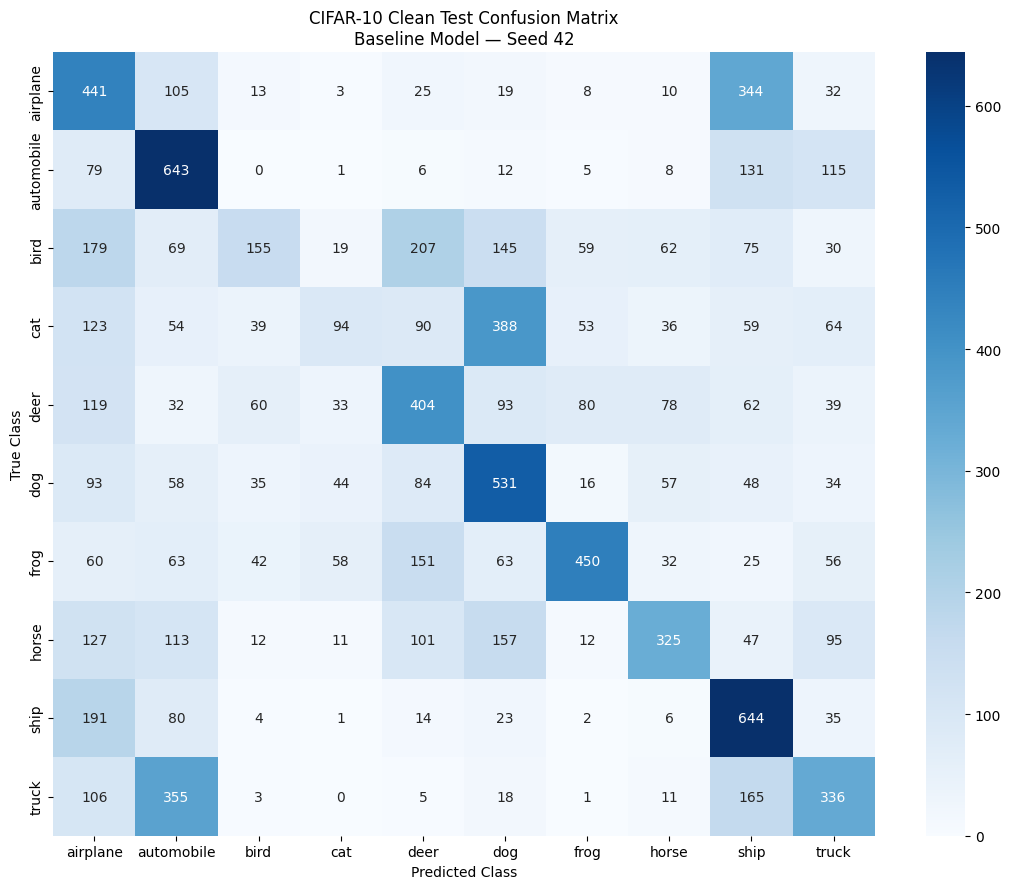


Total predictions: 10000
Correct predictions: 4023
Accuracy: 40.23%
Confusion matrix saved!


In [56]:

import os
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed representative seed (not selected using test accuracy)
ANALYSIS_SEED = 42

checkpoint_path = (
    f"experiment_results/baseline_seed{ANALYSIS_SEED}.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

analysis_model = SmallInceptionCNN().to(device)
analysis_model.load_state_dict(checkpoint["model_state_dict"])
analysis_model.eval()

all_true = []
all_pred = []

with torch.no_grad():
    for images, labels in clean_test_loader:

        images = images.to(device)
        outputs = analysis_model(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())

all_true = np.array(all_true)
all_pred = np.array(all_pred)

class_names = clean_test_dataset.classes

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(10))
)

per_class_accuracy = (
    cm.diagonal() / cm.sum(axis=1) * 100
)

print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        all_true,
        all_pred,
        labels=list(range(10)),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

print("\n========== PER-CLASS ACCURACY ==========")

for name, accuracy in zip(class_names, per_class_accuracy):
    print(f"{name:12s}: {accuracy:.2f}%")

# Save per-class accuracy
import pandas as pd

pd.DataFrame({
    "class": class_names,
    "accuracy_percent": per_class_accuracy
}).to_csv(
    "experiment_results/per_class_accuracy_seed42.csv",
    index=False
)

# Confusion matrix heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "CIFAR-10 Clean Test Confusion Matrix\n"
    "Baseline Model — Seed 42"
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.savefig(
    "experiment_results/confusion_matrix_seed42.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTotal predictions:", len(all_pred))
print("Correct predictions:", (all_true == all_pred).sum())
print(
    "Accuracy:",
    f"{(all_true == all_pred).mean() * 100:.2f}%"
)
print("Confusion matrix saved!")


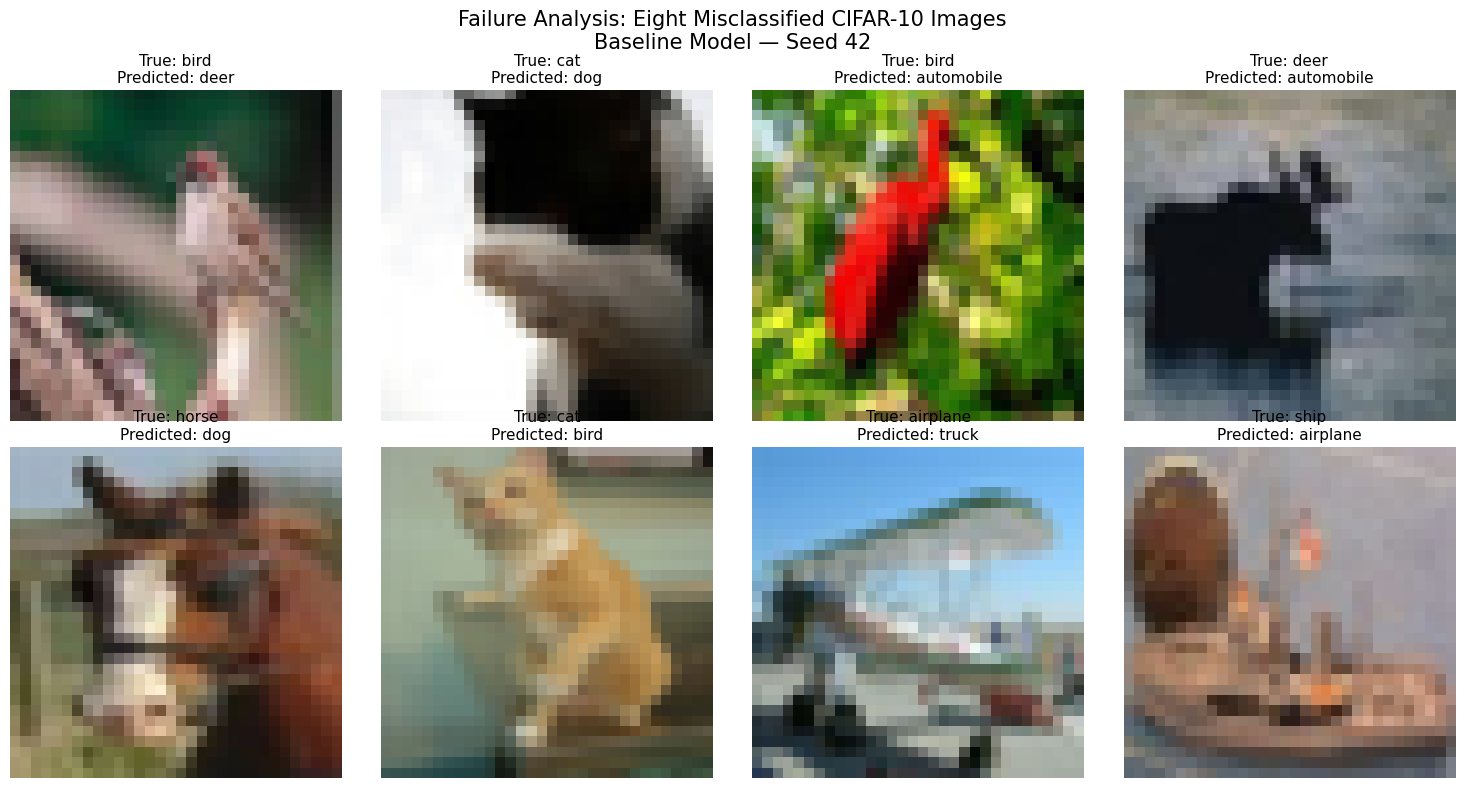

========== FAILURE ANALYSIS ==========
Total test images: 10000
Incorrect predictions: 5977
Selected failure examples: 8
Image 846: True=bird, Predicted=deer
Image 6942: True=cat, Predicted=dog
Image 8562: True=bird, Predicted=automobile
Image 6507: True=deer, Predicted=automobile
Image 4333: True=horse, Predicted=dog
Image 4400: True=cat, Predicted=bird
Image 886: True=airplane, Predicted=truck
Image 7707: True=ship, Predicted=airplane
Failure analysis figure saved!


In [57]:

import numpy as np
import matplotlib.pyplot as plt

# Find genuinely incorrect predictions
wrong_indices = np.where(all_true != all_pred)[0]

# Reproducible random selection
rng = np.random.default_rng(42)
selected_indices = rng.choice(
    wrong_indices,
    size=8,
    replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(15, 8))

for ax, idx in zip(axes.flat, selected_indices):

    # Raw original test image (without normalization)
    image = clean_test_dataset.data[idx]

    true_label = class_names[all_true[idx]]
    predicted_label = class_names[all_pred[idx]]

    ax.imshow(image)
    ax.set_title(
        f"True: {true_label}\n"
        f"Predicted: {predicted_label}",
        fontsize=11
    )
    ax.axis("off")

plt.suptitle(
    "Failure Analysis: Eight Misclassified CIFAR-10 Images\n"
    "Baseline Model — Seed 42",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "experiment_results/failure_examples_seed42.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== FAILURE ANALYSIS ==========")
print("Total test images:", len(all_true))
print("Incorrect predictions:", len(wrong_indices))
print("Selected failure examples:", len(selected_indices))

for idx in selected_indices:
    print(
        f"Image {idx}: "
        f"True={class_names[all_true[idx]]}, "
        f"Predicted={class_names[all_pred[idx]]}"
    )

print("Failure analysis figure saved!")


In [58]:

import random
import numpy as np
import torch

from PIL import Image
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader

SHIFT_SEED = 42

class SpecifiedShiftedCIFAR10(Dataset):

    def __init__(self, root="./data"):
        self.dataset = datasets.CIFAR10(
            root=root,
            train=False,
            download=False
        )

        self.mean = (0.4914, 0.4822, 0.4465)
        self.std = (0.2470, 0.2435, 0.2616)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        image, label = self.dataset[idx]

        # Local RNG: same image corruption across all models
        rng = random.Random(SHIFT_SEED + idx)

        # 1. Rotation: -25 to +25 degrees
        angle = rng.uniform(-25, 25)

        image = TF.rotate(
            image,
            angle=angle,
            interpolation=InterpolationMode.BILINEAR,
            fill=(0, 0, 0)
        )

        # 2. Brightness adjustment
        brightness = rng.uniform(0.7, 1.3)
        image = TF.adjust_brightness(image, brightness)

        # 3. Contrast adjustment
        contrast = rng.uniform(0.7, 1.3)
        image = TF.adjust_contrast(image, contrast)

        # 4. Approximately 25% rectangular occlusion
        width, height = image.size

        # 16 x 16 = 256 pixels = 25% of 32 x 32
        occ_w = width // 2
        occ_h = height // 2

        x = rng.randint(0, width - occ_w)
        y = rng.randint(0, height - occ_h)

        image = TF.to_tensor(image)

        image[:, y:y+occ_h, x:x+occ_w] = 0.0

        # 5. Normalize using the same CIFAR-10 statistics
        image = TF.normalize(
            image,
            mean=self.mean,
            std=self.std
        )

        return image, label


shifted_test_dataset = SpecifiedShiftedCIFAR10()

shifted_test_loader = DataLoader(
    shifted_test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

print("========== SHIFTED TEST DATASET ==========")
print("Images:", len(shifted_test_dataset))
print("Batches:", len(shifted_test_loader))
print("Rotation: ±25 degrees")
print("Brightness/Contrast: 0.7 to 1.3")
print("Occlusion: 25%")
print("Corruption seed:", SHIFT_SEED)
print("Hidden corruption: NOT PROVIDED")
print("Status: SPECIFIED-SHIFTS-ONLY (not official full shifted test)")

images, labels = next(iter(shifted_test_loader))

print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Shifted test loader ready!")


========== SHIFTED TEST DATASET ==========
Images: 10000
Batches: 79
Rotation: ±25 degrees
Brightness/Contrast: 0.7 to 1.3
Occlusion: 25%
Corruption seed: 42
Hidden corruption: NOT PROVIDED
Status: SPECIFIED-SHIFTS-ONLY (not official full shifted test)
Batch shape: torch.Size([128, 3, 32, 32])
Labels shape: torch.Size([128])
Shifted test loader ready!


In [59]:

import os
import json
import numpy as np
import pandas as pd

os.makedirs("experiment_results", exist_ok=True)

shifted_results = []

print("========== SHIFTED TEST EVALUATION ==========")
print("Mode: Specified shifts only")
print("Hidden corruption: NOT PROVIDED")
print("Total models:", len(CONFIGS) * len(SEEDS))
print()

for config in CONFIGS:
    for seed in SEEDS:

        result = evaluate_checkpoint(
            config=config,
            seed=seed,
            test_loader=shifted_test_loader
        )

        shifted_results.append(result)

        print(
            f"{config:25s} | "
            f"Seed {seed} | "
            f"Accuracy: {result['accuracy']:.2f}%"
        )

# Save individual seed results
shifted_df = pd.DataFrame(shifted_results)

shifted_df.to_csv(
    "experiment_results/specified_shifts_results.csv",
    index=False
)

# Mean ± sample standard deviation
shifted_summary = (
    shifted_df.groupby("configuration")["accuracy"]
    .agg(
        shifted_mean="mean",
        shifted_std="std",
        count="count"
    )
    .reset_index()
)

# Merge with existing clean-test results
clean_data = pd.read_csv(
    "experiment_results/all_clean_test_results.csv"
)

comparison = clean_data[
    ["configuration", "seed", "accuracy"]
].rename(columns={"accuracy": "clean_accuracy"})

shifted_for_merge = shifted_df[
    ["configuration", "seed", "accuracy"]
].rename(columns={"accuracy": "shifted_accuracy"})

comparison = comparison.merge(
    shifted_for_merge,
    on=["configuration", "seed"],
    validate="one_to_one"
)

assert len(comparison) == 21

# Drop in percentage points for each paired seed
comparison["drop_pp"] = (
    comparison["clean_accuracy"] -
    comparison["shifted_accuracy"]
)

comparison.to_csv(
    "experiment_results/clean_vs_shifted_per_seed.csv",
    index=False
)

# Configuration-level summary
final_summary = (
    comparison.groupby("configuration")
    .agg(
        clean_mean=("clean_accuracy", "mean"),
        clean_std=("clean_accuracy", "std"),
        shifted_mean=("shifted_accuracy", "mean"),
        shifted_std=("shifted_accuracy", "std"),
        drop_mean_pp=("drop_pp", "mean"),
        drop_std_pp=("drop_pp", "std"),
        count=("seed", "count")
    )
    .reset_index()
)

assert len(final_summary) == 7
assert (final_summary["count"] == 3).all()

# Display in experimental order
final_summary = (
    final_summary.set_index("configuration")
    .loc[CONFIGS]
    .reset_index()
)

final_summary.to_csv(
    "experiment_results/robustness_summary.csv",
    index=False
)

print("\n========== ROBUSTNESS SUMMARY ==========")

for _, row in final_summary.iterrows():
    print(
        f"{row['configuration']:25s} | "
        f"Clean: {row['clean_mean']:.2f} ± "
        f"{row['clean_std']:.2f}% | "
        f"Shifted: {row['shifted_mean']:.2f} ± "
        f"{row['shifted_std']:.2f}% | "
        f"Drop: {row['drop_mean_pp']:.2f} pp"
    )

# Record the evaluation assumptions
protocol = {
    "dataset": "CIFAR-10 original test split",
    "num_images": 10000,
    "models": 21,
    "shift_seed": 42,
    "rotation_degrees": [-25, 25],
    "brightness_factor": [0.7, 1.3],
    "contrast_factor": [0.7, 1.3],
    "occlusion": "16x16 black rectangle",
    "hidden_corruption": "NOT PROVIDED",
    "result_status": "Specified-shifts-only evaluation",
    "official_full_shifted_test": False,
    "model_selection": "Locked using validation only"
}

with open(
    "experiment_results/shift_protocol.json",
    "w"
) as f:
    json.dump(protocol, f, indent=4)

print("\n========== VERIFICATION ==========")
print("Models evaluated:", len(shifted_df))
print("Configurations:", len(final_summary))
print("Seeds per configuration: 3")
print("Official hidden corruption: PENDING")
print("CSV and protocol files saved!")


========== SHIFTED TEST EVALUATION ==========
Mode: Specified shifts only
Hidden corruption: NOT PROVIDED
Total models: 21

baseline                  | Seed 42 | Accuracy: 16.88%
baseline                  | Seed 123 | Accuracy: 18.83%
baseline                  | Seed 2026 | Accuracy: 19.01%
geometric                 | Seed 42 | Accuracy: 24.49%
geometric                 | Seed 123 | Accuracy: 25.26%
geometric                 | Seed 2026 | Accuracy: 23.38%
photometric               | Seed 42 | Accuracy: 22.73%
photometric               | Seed 123 | Accuracy: 20.83%
photometric               | Seed 2026 | Accuracy: 16.40%
combined                  | Seed 42 | Accuracy: 22.95%
combined                  | Seed 123 | Accuracy: 26.67%
combined                  | Seed 2026 | Accuracy: 22.14%
combined_cutout           | Seed 42 | Accuracy: 23.74%
combined_cutout           | Seed 123 | Accuracy: 25.35%
combined_cutout           | Seed 2026 | Accuracy: 26.33%
combined_cutout_mixup     | Seed 42 

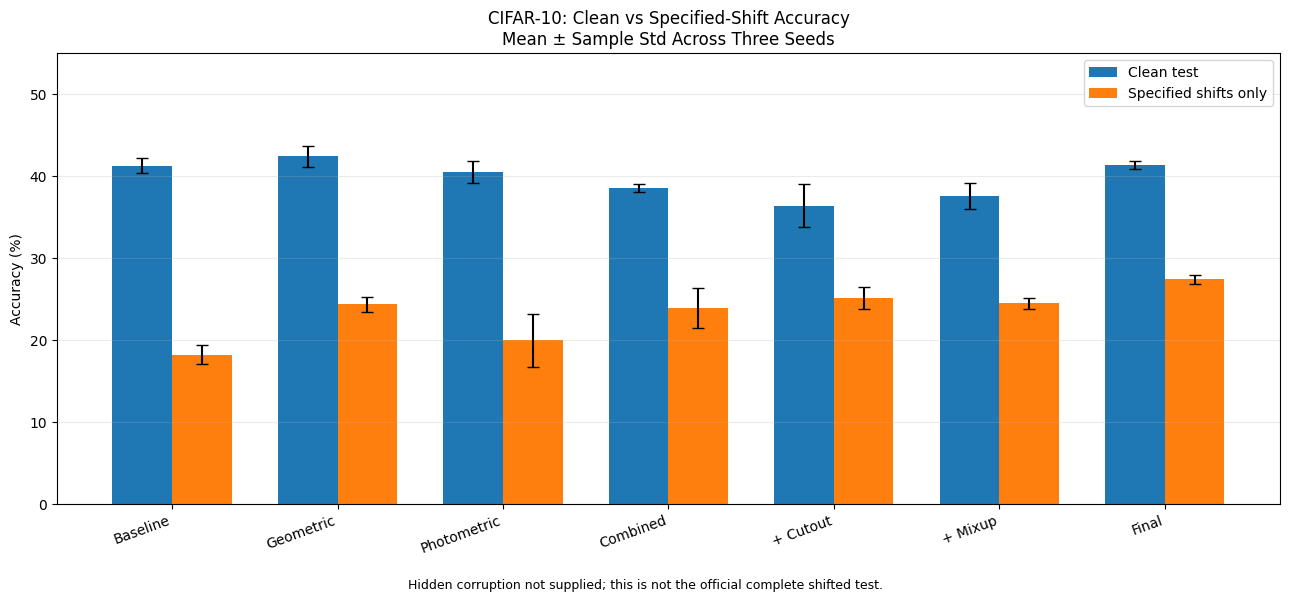

========== FINAL GRAPH ==========
Saved: experiment_results/clean_vs_specified_shifts.png
Configurations: 7
Hidden corruption: PENDING


In [60]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

df = pd.read_csv(
    "experiment_results/robustness_summary.csv"
)

labels = [
    "Baseline", "Geometric", "Photometric",
    "Combined", "+ Cutout", "+ Mixup", "Final"
]

x = np.arange(len(df))
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    x - width/2,
    df["clean_mean"],
    width,
    yerr=df["clean_std"],
    capsize=4,
    label="Clean test"
)

ax.bar(
    x + width/2,
    df["shifted_mean"],
    width,
    yerr=df["shifted_std"],
    capsize=4,
    label="Specified shifts only"
)

ax.set_title(
    "CIFAR-10: Clean vs Specified-Shift Accuracy\n"
    "Mean ± Sample Std Across Three Seeds"
)
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylim(0, 55)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.text(
    0.5, 0.01,
    "Hidden corruption not supplied; "
    "this is not the official complete shifted test.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

output_path = (
    "experiment_results/"
    "clean_vs_specified_shifts.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("========== FINAL GRAPH ==========")
print("Saved:", output_path)
print("Configurations:", len(df))
print("Hidden corruption: PENDING")


In [61]:

import os
import zipfile
import json
from datetime import datetime, timezone

from google.colab import drive

# Mount Drive if necessary
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

BACKUP_DIR = (
    "/content/drive/MyDrive/"
    "DL_Assignment2_Backup_23F_0632"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

FINAL_ZIP = os.path.join(
    BACKUP_DIR,
    "Section_B_Experiments_Backup.zip"
)

TEMP_ZIP = os.path.join(
    BACKUP_DIR,
    "Section_B_Experiments_Backup_NEW.zip"
)

configs = [
    "baseline",
    "geometric",
    "photometric",
    "combined",
    "combined_cutout",
    "combined_cutout_mixup",
    "final_candidate"
]

seeds = [42, 123, 2026]

# Verify all 21 trained models
required_checkpoints = [
    f"experiment_results/{config}_seed{seed}.pth"
    for config in configs
    for seed in seeds
]

# Verify important final result files
required_outputs = [
    "experiment_results/validation_summary.csv",
    "experiment_results/all_clean_test_results.csv",
    "experiment_results/clean_test_summary.csv",
    "experiment_results/specified_shifts_results.csv",
    "experiment_results/clean_vs_shifted_per_seed.csv",
    "experiment_results/robustness_summary.csv",
    "experiment_results/model_selection.json",
    "experiment_results/shift_protocol.json",
    "experiment_results/ablation_validation.png",
    "experiment_results/confusion_matrix_seed42.png",
    "experiment_results/failure_examples_seed42.png",
    "experiment_results/clean_vs_specified_shifts.png"
]

required_files = required_checkpoints + required_outputs

missing = [
    file for file in required_files
    if not os.path.isfile(file)
]

if missing:
    print("MISSING FILES:")
    for file in missing:
        print("-", file)
    raise FileNotFoundError(
        "Backup stopped. Fix missing files first."
    )

# Record backup metadata
metadata = {
    "assignment": "Deep Learning for Perception - Assignment 2",
    "student_id": "23F-0632",
    "checkpoints": 21,
    "train_seeds": seeds,
    "clean_test": "Complete",
    "specified_shifts_evaluation": "Complete",
    "hidden_corruption": "Not provided by instructor",
    "official_full_shifted_test": "Pending",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

metadata_path = (
    "experiment_results/backup_manifest.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Collect entire experiments directory
files_to_backup = []

for root, dirs, filenames in os.walk(
    "experiment_results"
):
    for filename in filenames:
        path = os.path.join(root, filename)
        files_to_backup.append(path)

# Include standalone CSV/PNG/PTH files
for filename in os.listdir("."):
    if (
        os.path.isfile(filename)
        and filename.endswith(
            (".pth", ".csv", ".png", ".json")
        )
    ):
        files_to_backup.append(filename)

files_to_backup = sorted(set(files_to_backup))

# Build temporary ZIP
with zipfile.ZipFile(
    TEMP_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for file in files_to_backup:
        z.write(file, arcname=file)

# Verify before replacing old backup
with zipfile.ZipFile(TEMP_ZIP, "r") as z:
    inside = set(z.namelist())
    corrupt = z.testzip()

    missing_in_zip = [
        file for file in required_files
        if file not in inside
    ]

    if metadata_path not in inside:
        missing_in_zip.append(metadata_path)

    checkpoint_count = sum(
        1 for f in required_checkpoints
        if f in inside
    )

if corrupt is not None or missing_in_zip:
    raise RuntimeError(
        "Backup verification failed: "
        + str(missing_in_zip)
    )

# Replace previous ZIP after successful verification
os.replace(TEMP_ZIP, FINAL_ZIP)

print("========== FINAL BACKUP VERIFIED ==========")
print("ZIP integrity: PASS")
print("Required checkpoints:", checkpoint_count, "/21")
print("Required output files:", len(required_outputs), "/12")
print("Total archived files:", len(files_to_backup))
print(
    "ZIP size:",
    round(os.path.getsize(FINAL_ZIP) / 1024**2, 2),
    "MB"
)
print("Hidden corruption: PENDING")
print("Backup location:", FINAL_ZIP)
print("SUCCESS: Final experiment backup complete!")


========== FINAL BACKUP VERIFIED ==========
ZIP integrity: PASS
Required checkpoints: 21 /21
Required output files: 12 /12
Total archived files: 44
ZIP size: 8.99 MB
Hidden corruption: PENDING
Backup location: /content/drive/MyDrive/DL_Assignment2_Backup_23F_0632/Section_B_Experiments_Backup.zip
SUCCESS: Final experiment backup complete!
